# ML-10 — Content Action Playbook

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

**Lane 2, Refresh / Content Opportunity Scoring.** The question is the same since W01: which pages should a reviewer look at first? W04 gave me a frozen rule, W05 a model and W06 an honest validation. This notebook turns that validated output into a playbook a content team could use: what to do with each page, in which order, why, what a person must check first, what must never be automated and what would tell us the queue went stale.

**Same frame as W03 to W06:** one row = one page, features from one month and the decision on its last day. I run the playbook twice, as a team would run it every month:

| Run | Decision day | Features | Normal level of the page | Model learns from | Checked on (hindsight only) |
|---|---|---|---|---|---|
| 1 (main) | 31 March 2026 | March | February | Feb→Mar labels (known by 31 March) | April |
| 2 | 30 April 2026 | April | March | Mar→Apr labels (known by 30 April) | May |

The exported queue is run 1. June 2026, the sealed month, is never read here. I keep it for the capstone.

**Short version:**
- **The rule explains, the model orders, the clicks size it.** Every row carries a reason code from the frozen W04 rule (`sliding_with_demand` or `NO_FLAG`) and an action a person can do. The order is the model score times the clicks a day the page lost against its own previous month.
- **Why not the model score alone:** in both runs the first 50 rows ordered by the model held about 2 clicks a day that were still lost the next month. The playbook order held about 530 to 550. Half or more of the rows the model puts first had no click at all in the month.
- **The decay/refresh insight:** the W03 label scores a surge that ended about the same as a real drop (71% vs 72% "declined" on 31 March). The page's own previous month tells them apart: 84% of the real drops were still below normal a month later against 41% of the ended surges.
- **What it does not say:** the queue does not forecast new falls. On the strict W06 label (did the page fall another 20% after the decision day?) the batch scored 36% on 31 March and 56% on 30 April against a pool base rate of 50%. Nothing here measures what a refresh does either. The queue says "already down and staying down, with visits at stake". It never says "about to drop" or "will recover if refreshed".

**How to run it:** same as W03 to W06. In Colab save your Hugging Face READ token as a Secret named `HF_TOKEN`. Outside Colab the notebook reads the `HF_TOKEN` environment variable or asks for it with `getpass`. The token is never printed and never written into the notebook. The notebook reads the February to May partitions (about a minute). There is no random step: the models are logistic regressions and every tie is broken by `content_hash_id`, so a rerun gives the same tables.

In [1]:
%pip install -q duckdb huggingface_hub pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import getpass
import platform
from datetime import date
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The repo is public, so the token comes from a Colab Secret or an environment variable.
# It is never printed. getpass is only the last fallback.
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass
HF_TOKEN = HF_TOKEN or os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face READ token: ")

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
con.execute("SET enable_progress_bar = false")     # keeps the saved outputs clean
print("DuckDB connected. Hugging Face token loaded (not printed).")
VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
            "numpy": np.__version__, "duckdb": duckdb.__version__, "matplotlib": matplotlib.__version__}
print("Versions:", " | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

# Works from work/notebooks/ (local clone) and from Colab (/content)
OUT_DIR = Path("../outputs") if Path.cwd().name == "notebooks" else Path("work/outputs")
FIG_DIR = Path("../figures") if Path.cwd().name == "notebooks" else Path("work/figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

DuckDB connected. Hugging Face token loaded (not printed).
Versions: python 3.13.17 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | duckdb 2.0.0 | matplotlib 3.11.2


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### What I carry over from W04 to W06

The playbook should not invent new evidence. It should turn what the earlier weeks found into rules a person can follow. The cell below reads the committed receipts so the numbers here can't drift from those notebooks.

| Finding | Week | What the playbook does with it |
|---|---|---|
| The late-month slide is the strongest signal, but part of a "slide" is a surge ending | W04, W04 audit | the slide alone never sends a page to refresh. The page's level in the previous month decides if the drop is real |
| CTR low for its position was CONFIRMED in two month pairs | W04 audit | shown as a context code, so the reviewer checks the title and snippet first |
| Volume points the wrong way as a risk signal (OPPOSITE) | W04 | volume never decides who is at risk. Clicks only size the order |
| The rule's top 50 are big pages, the model's top 50 are small pages with no clicks | W05 | the order multiplies the model score by the clicks at stake |
| Trained only on the past, the model ties the slide-only sort and is not reliably above the rule | W06 | the model is kept as the risk part of the order, with a fallback if it keeps losing (section 4) |
| 43% of the W05 top-50 hits were carry-over. On "fell after 31 March" everything is at the base rate | W06 | the playbook says "already down", never "about to drop" |
| Young pages and young growing clients cause most false alarms | W05, W06 | young pages stay off the queue until they have a full month |
| One client can fill the top 50 | W04, W06 | whole-client drops go to one site check. A crowded batch gets a site-level look first |

In [3]:
def receipt(name):
    path = OUT_DIR / name
    return json.loads(path.read_text()) if path.exists() else None


def from_receipt(data, keys, fallback):
    """One number from a committed receipt. Falls back to the number printed in that notebook (e.g. in Colab)."""
    try:
        for key in keys:
            data = data[key]
        return data
    except (TypeError, KeyError):
        return fallback


w04, audit, w05, w06 = (receipt(n) for n in ["w04_baseline_metrics.json", "w04_signal_audit_verdicts.json",
                                             "w05_model_metrics.json", "w06_validation_audit_metrics.json"])
mar, apr = ["mar_apr_test", "mean_over_folds"], ["apr_may_test", "mean_over_folds"]
CARRIED = pd.DataFrame([
    ("W04 audit", "late-month slide", from_receipt(audit, ["verdicts", "#1 late-month slide", "verdict"], "CONFIRMED")),
    ("W04 audit", "CTR low for its position (CTR-fix flag)", from_receipt(audit, ["verdicts", "flag: CTR low for its position (CTR-fix)", "verdict"], "CONFIRMED")),
    ("W04", "volume as a risk signal (quick-win)", from_receipt(w04, ["signal_verdicts", "A_volume_quick_win"], "OPPOSITE")),
    ("W05", "rule top 50: median impressions a day", from_receipt(w05, ["top50_profile", "W04 rule (baseline)", "median impressions per day (March)"], 872.871)),
    ("W05", "model top 50: median impressions a day", from_receipt(w05, ["top50_profile", "logistic regression", "median impressions per day (March)"], 32.1452)),
    ("W05", "model top 50: share with 0 clicks in March", from_receipt(w05, ["top50_profile", "logistic regression", "share with 0 clicks in March"], 0.608)),
    ("W06", "Mar→Apr P@50: random / rule / slide only", "{:.3f} / {:.3f} / {:.3f}".format(
        from_receipt(w06, mar + ["random order", "P@50"], 0.5034), from_receipt(w06, mar + ["W04 rule (baseline)", "P@50"], 0.784),
        from_receipt(w06, mar + ["slide only (no model)", "P@50"], 0.8))),
    ("W06", "Mar→Apr P@50: model, time-aware (C) / time-aware + grouped (D)", "{:.3f} / {:.3f}".format(
        from_receipt(w06, mar + ["logistic regression, C", "P@50"], 0.748), from_receipt(w06, mar + ["logistic regression, D", "P@50"], 0.776))),
    ("W06", "Apr→May P@50: random / rule / slide only", "{:.3f} / {:.3f} / {:.3f}".format(
        from_receipt(w06, apr + ["random order", "P@50"], 0.5811), from_receipt(w06, apr + ["W04 rule (baseline)", "P@50"], 0.884),
        from_receipt(w06, apr + ["slide only (no model)", "P@50"], 0.98))),
    ("W06", "Apr→May P@50: model, time-aware (C) / time-aware + grouped (D)", "{:.3f} / {:.3f}".format(
        from_receipt(w06, apr + ["logistic regression, C", "P@50"], 0.988), from_receipt(w06, apr + ["logistic regression, D", "P@50"], 0.988))),
    ("W06", "W05 top-50 hits that did not fall another 20% after 31 March",
     from_receipt(w06, ["carry_over_share", "hits in the top 50s: logistic regression, B (W05)"], 0.4299)),
], columns=["week", "finding", "number"])
print("Read from the committed receipts" if all(r is not None for r in (w04, audit, w05, w06)) else "Some receipts missing: used the numbers printed in those notebooks")
with pd.option_context("display.max_colwidth", 90):
    display(CARRIED.set_index(["week", "finding"]))

Read from the committed receipts


number
week      finding                                                                              
W04 audit late-month slide                                                            CONFIRMED
          CTR low for its position (CTR-fix flag)                                     CONFIRMED
W04       volume as a risk signal (quick-win)                                          OPPOSITE
W05       rule top 50: median impressions a day                                         872.871
          model top 50: median impressions a day                                        32.1452
          model top 50: share with 0 clicks in March                                      0.608
W06       Mar→Apr P@50: random / rule / slide only                        0.503 / 0.784 / 0.800
          Mar→Apr P@50: model, time-aware (C) / time-aware + grouped (D)          0.748 / 0.776
          Apr→May P@50: random / rule / slide only                        0.581 / 0.884 / 0.980
          Apr→May P@50: model, time-aware (C) / time-aware + grouped (D)          0.988 / 0.988
          W05 top-50 hits that did not fall another 20% after 31 March                   0.4299

These are the numbers the playbook starts from. Two of them set the tone. In W06 my model was level with the frozen rule on 31 March (0.776 vs 0.784 with the strictest split) and above it on 30 April (0.988 vs 0.884). A plain slide sort was at least as good as the model in both months. So the model has not earned the right to rank on its own. Section 1 tests what it adds when it is combined with the clicks at stake.

### Rebuild the frames and check them against W06

One query per month (February to May) sums each page's daily rows, the same sums as W06 plus three columns the playbook needs: clicks in the second half of the month and the biggest single day of the first half. Then one function builds a page frame with the four W03 eligibility rules. The labels and the next-month numbers go into a separate hindsight table. The playbook never sees that table. I only join it after every order is fixed, to judge the result.

In [4]:
REL = "hf://datasets/FlyRank/internship-warehouse"
LABEL = "declined_next_month"            # W03 label: next month per day more than 20% below the feature month average
STRICT_LABEL = "fell_after_decision"     # W06 check: next month more than 20% below the SECOND half of the feature month
DECLINE_CUTOFF_PCT = -20
MIN_IMPRESSIONS = 100                    # W03 data contract floor
MIN_SLIDE_PCT, MIN_LATE_PER_DAY = 20, 5  # the frozen W04 rule. The 5-a-day bar is also the W05 review pool
FEATURES = ["imp_per_day_log", "ctr_pct", "avg_position", "late_half_share", "gsc_days"]   # the W05 / W06 model, unchanged
SEED, N_FOLDS, BATCH = 42, 5, 50         # BATCH: the team reviews about 50 pages a month (precision@50 since W02)
K_GRID = [10, 20, 30, 50, 75, 100, 150, 200]
LATE_HALF_START = {"2026-02": "2026-02-15", "2026-03": "2026-03-16", "2026-04": "2026-04-16", "2026-05": "2026-05-16"}

# Playbook cuts. Every one is reused from an earlier week. None was tuned in this notebook
BELOW_NORMAL = 0.8      # second half under 80% of the previous month's level: the same 20% cut as the label
SPIKE_SHARE = 0.30      # one day holds 30%+ of the first half's impressions (the W04 weak-pick check)
SITE_DROP = 0.8         # the whole client's second half under 80% of its previous month (same 20% cut)
CTR_TIERS = [1, 3, 10, 20]               # the W04 audit tiers for "CTR low for its position"

# Two monthly runs: (feature month, label month, previous month). The label month is only read as hindsight
RUNS = {"31 March": ("2026-03", "2026-04", "2026-02"), "30 April": ("2026-04", "2026-05", "2026-03")}
TRAIN_SLICE = {"31 March": "Feb→Mar", "30 April": "Mar→Apr"}   # the model for each run learns only from labels known by then
print("Decision days:", ", ".join(RUNS), "| June 2026 (sealed) is never read")

Decision days: 31 March, 30 April | June 2026 (sealed) is never read


In [5]:
def month_pages(month):
    """One row per page for one month partition: the W06 sums plus clicks per half and the biggest first-half day."""
    late = LATE_HALF_START[month]
    return con.sql(f'''
        SELECT
            content_hash_id,
            ANY_VALUE(client_hash_id)                           AS client_hash_id,  -- safe: W03 query 1 showed one client per page
            COUNT(*)                                            AS n_rows,
            SUM(gsc_impressions)::BIGINT                        AS imp,
            SUM(gsc_clicks)::BIGINT                             AS clicks,
            SUM(gsc_impressions) FILTER (WHERE report_date >= DATE '{late}')::BIGINT AS imp_late,
            SUM(gsc_clicks)      FILTER (WHERE report_date >= DATE '{late}')::BIGINT AS clicks_late,
            MAX(gsc_impressions) FILTER (WHERE report_date <  DATE '{late}')::BIGINT AS early_peak_day,
            COUNT(*) FILTER (WHERE gsc_data_available IS TRUE)  AS gsc_days,
            SUM(gsc_sum_position) FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_sum,
            SUM(gsc_impressions)  FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_impressions,
            MIN(report_date)                                    AS first_date,
            MAX(report_date)                                    AS last_date
        FROM read_parquet('{REL}/fact_content_daily_performance/month={month}/*.parquet')
        GROUP BY content_hash_id
    ''').df()


MONTHS = {m: month_pages(m) for m in LATE_HALF_START}      # February to May. June (sealed) is never read
clients = con.sql(f"SELECT client_hash_id, gsc_data_start FROM read_parquet('{REL}/dim_clients.parquet')").df()
pd.DataFrame({m: {"pages": len(d), "first day read": d["first_date"].min(), "last day read": d["last_date"].max()}
              for m, d in MONTHS.items()}).T

,pages,first day read,last day read
2026-02,321546,2026-02-01 00:00:00,2026-02-28 00:00:00
2026-03,331437,2026-03-01 00:00:00,2026-03-31 00:00:00
2026-04,362172,2026-04-01 00:00:00,2026-04-30 00:00:00
2026-05,389153,2026-05-01 00:00:00,2026-05-31 00:00:00


In [6]:
def page_frame(feature_month, label_month, prev_month=None):
    """One row per page with the W03 rules. Features from feature_month, the page's normal level from prev_month.
    The labels go into a separate hindsight table that is only joined after the queue is built."""
    f, lab = MONTHS[feature_month], MONTHS[label_month]
    first_day = pd.Timestamp(f"{feature_month}-01")
    f_days, l_days = first_day.days_in_month, pd.Timestamp(f"{label_month}-01").days_in_month
    early_days = (pd.Timestamp(LATE_HALF_START[feature_month]) - first_day).days
    late_days = f_days - early_days
    raw = (f.merge(clients, on="client_hash_id", how="left")
            .merge(lab[["content_hash_id", "n_rows", "imp", "clicks"]]
                   .rename(columns={"n_rows": "label_rows", "imp": "imp_label", "clicks": "clicks_label"}), on="content_hash_id", how="left"))
    if prev_month:
        raw = raw.merge(MONTHS[prev_month][["content_hash_id", "n_rows", "imp", "clicks"]]
                        .rename(columns={"n_rows": "prev_rows", "imp": "imp_prev", "clicks": "clicks_prev"}), on="content_hash_id", how="left")
    counts = [c for c in raw.columns if c not in ("content_hash_id", "client_hash_id", "gsc_data_start", "first_date", "last_date")]
    raw[counts] = raw[counts].astype("float64")           # SQL NULL becomes NaN
    raw["gsc_data_start"] = pd.to_datetime(raw["gsc_data_start"])
    keep = (raw["n_rows"].eq(f_days) & raw["gsc_data_start"].le(first_day)          # the four W03 eligibility rules
            & raw["imp"].ge(MIN_IMPRESSIONS) & raw["label_rows"].eq(l_days))
    e = raw[keep].sort_values("content_hash_id").reset_index(drop=True)

    d = pd.DataFrame({
        "content_hash_id": e["content_hash_id"],
        "client_hash_id": e["client_hash_id"],
        # the five model features (feature month only, same as W06)
        "imp_per_day_log": np.log1p(e["imp"] / f_days),
        "ctr_pct": 100 * e["clicks"] / e["imp"],
        "avg_position": e["position_sum"] / e["position_impressions"],
        "late_half_share": e["imp_late"] / e["imp"],
        "gsc_days": e["gsc_days"] * 31 / f_days,
        # rule inputs and playbook columns (feature month only)
        "imp_per_day": e["imp"] / f_days,
        "early_per_day": (e["imp"] - e["imp_late"]) / early_days,
        "late_per_day": e["imp_late"] / late_days,
        "clicks_per_day": e["clicks"] / f_days,
        "clicks_late_per_day": e["clicks_late"] / late_days,
    })
    d["slide_pct"] = 100 * (1 - d["late_per_day"] / d["early_per_day"].where(d["early_per_day"] > 0))
    early_imp = e["imp"] - e["imp_late"]
    d["early_peak_share"] = e["early_peak_day"] / early_imp.where(early_imp > 0)
    d["in_pool"] = d["late_per_day"] >= MIN_LATE_PER_DAY                 # the W05 review pool
    if prev_month:   # the page's normal level: only when it has every day of the previous month and its client was tracked
        prev_first = pd.Timestamp(f"{prev_month}-01")
        full_prev = e["prev_rows"].eq(prev_first.days_in_month) & e["gsc_data_start"].le(prev_first) & e["imp_prev"].gt(0)
        d["prev_per_day"] = (e["imp_prev"] / prev_first.days_in_month).where(full_prev)
        d["prev_clicks_per_day"] = (e["clicks_prev"] / prev_first.days_in_month).where(full_prev)

    # Labels and next-month numbers: hindsight, kept OUT of the frame
    next_per_day = e["imp_label"] / l_days
    change_pct = 100 * (next_per_day - d["imp_per_day"]) / d["imp_per_day"]
    vs_late_pct = 100 * (next_per_day - d["late_per_day"]) / d["late_per_day"].where(d["late_per_day"] > 0)
    hindsight = pd.DataFrame({LABEL: (change_pct < DECLINE_CUTOFF_PCT).astype(int).to_numpy(),
                              STRICT_LABEL: (vs_late_pct < DECLINE_CUTOFF_PCT).astype(int).to_numpy(),
                              "next_per_day": next_per_day.to_numpy(),
                              "next_clicks_per_day": (e["clicks_label"] / l_days).to_numpy()},
                             index=e["content_hash_id"])
    assert d["content_hash_id"].is_unique, "grain broken: expected one row per page"
    return d, hindsight


FRAMES, HIND = {}, {}
FRAMES["Feb→Mar"], HIND["Feb→Mar"] = page_frame("2026-02", "2026-03")       # training slice for the 31 March run
FRAMES["Mar→Apr"], HIND["Mar→Apr"] = page_frame("2026-03", "2026-04", "2026-02")   # run 1: decision on 31 March
FRAMES["Apr→May"], HIND["Apr→May"] = page_frame("2026-04", "2026-05", "2026-03")   # run 2: decision on 30 April
RUN_SLICE = {"31 March": "Mar→Apr", "30 April": "Apr→May"}

for name, d in FRAMES.items():
    assert not set(d.columns) & {LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"}, "a label leaked into a frame"


def labels(slice_name, pages, column=LABEL):
    """Hindsight for a set of pages, joined by content_hash_id (only used after scoring, or for training slices)."""
    return HIND[slice_name][column].reindex(pages["content_hash_id"]).to_numpy()


w06_slices = from_receipt(w06, ["slices"], {
    "Feb→Mar": {"pages": 64881, "clients": 26, "base_rate": 0.2484, "pool_pages": 60290, "pool_base_rate": 0.2402},
    "Mar→Apr": {"pages": 94496, "clients": 38, "base_rate": 0.5159, "pool_pages": 84592, "pool_base_rate": 0.4973},
    "Apr→May": {"pages": 99868, "clients": 44, "base_rate": 0.5835, "pool_pages": 84691, "pool_base_rate": 0.5729}})
rows = {}
for name, d in FRAMES.items():
    pool_d = d[d["in_pool"]]
    got = {"pages": len(d), "clients": d["client_hash_id"].nunique(), "base_rate": round(float(labels(name, d).mean()), 4),
           "pool_pages": len(pool_d), "pool_base_rate": round(float(labels(name, pool_d).mean()), 4)}
    rows[name] = {**got, "same as W06": got == {k: w06_slices[name][k] for k in got}}
    if "prev_per_day" in d:
        rows[name]["pool pages with a full previous month"] = f"{pool_d['prev_per_day'].notna().mean():.1%}"
checks = pd.DataFrame(rows).T
assert checks["same as W06"].all(), "a frame drifted from W06"
print("PASS  all three slices match the W06 receipt (pages, clients, base rate, review pool)")
checks

PASS  all three slices match the W06 receipt (pages, clients, base rate, review pool)


,pages,clients,base_rate,pool_pages,pool_base_rate,same as W06,pool pages with a full previous month
Feb→Mar,64881,26,0.2484,60290,0.2402,True,NaN
Mar→Apr,94496,38,0.5159,84592,0.4973,True,75.1%
Apr→May,99868,44,0.5835,84691,0.5729,True,87.3%


All three slices match the W06 receipt exactly (pages, clients, base rate, review pool and its base rate). In the review pool 75.1% of the 31 March pages and 87.3% of the 30 April pages have a full previous month, so they have a known normal level. The rest are new pages or pages of clients that started tracking late. They are the "young pages" that W05 and W06 found behind most false alarms.

### The model and the frozen rule on the same folds (the validated view)

The model is unchanged from W05 and W06: a logistic regression on the five W03 features, trained only on labels that are complete on the decision day. For the queue I train it on the whole previous slice (W06 design C), because on a real decision day a team would use every client's last month. Next to it I rebuild the strictest W06 version (design D, the test clients also held out) as a check. The frozen W04 rule and a plain sort by the slide have nothing to train.

The cell checks that both model versions give back the W06 P@50 exactly, then draws the precision@K curve on the same five client folds. The shaded part is the review budget: about 50 pages a month.

In [7]:
def logistic_regression():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def rank_order(scores, ids):
    # Highest score first. Ties are broken by content_hash_id, the same fixed order as W04 to W06
    return np.lexsort((np.asarray(ids), -np.asarray(scores, dtype=float)))


def sliding_with_demand(pages):
    # The W04 baseline rule, frozen. Reads only two feature-month columns
    early, late = pages["early_per_day"], pages["late_per_day"]
    slide_pct = 100 * (1 - late / early.where(early > 0))
    fires = slide_pct.ge(MIN_SLIDE_PCT) & late.ge(MIN_LATE_PER_DAY)
    return pd.Series(np.where(fires, early - late, 0.0), index=pages.index)


def client_folds(frame):
    # GroupKFold on ALL pages of a slice grouped by client: the same five folds as W04 to W06 (GroupKFold ignores y)
    fold = np.full(len(frame), -1)
    for k, (_, test_idx) in enumerate(GroupKFold(n_splits=N_FOLDS).split(frame, groups=frame["client_hash_id"])):
        fold[test_idx] = k
    return fold


for name in FRAMES:
    FRAMES[name]["fold"] = client_folds(FRAMES[name])
POOLS = {name: d[d["in_pool"]].reset_index(drop=True) for name, d in FRAMES.items()}

# The queue model for each run: trained on the previous slice's review pool, all clients (W06 design C).
# Its labels are complete on the decision day, so nothing from the label month is used
QUEUE_MODEL = {run: logistic_regression().fit(POOLS[TRAIN_SLICE[run]][FEATURES], labels(TRAIN_SLICE[run], POOLS[TRAIN_SLICE[run]]))
               for run in RUNS}

SCORES = {}
for run, s in RUN_SLICE.items():
    pool, train = POOLS[s], POOLS[TRAIN_SLICE[run]]
    d_scores = np.full(len(pool), np.nan)    # W06 design D: same model, also without the test fold's clients
    for k in range(N_FOLDS):
        test = (pool["fold"] == k).to_numpy()
        part = train[~train["client_hash_id"].isin(set(pool.loc[test, "client_hash_id"]))]
        d_scores[test] = logistic_regression().fit(part[FEATURES], labels(TRAIN_SLICE[run], part)).predict_proba(pool.loc[test, FEATURES])[:, 1]
    SCORES[run] = {"queue model (time-aware, C)": QUEUE_MODEL[run].predict_proba(pool[FEATURES])[:, 1],
                   "same model, test clients held out (D)": d_scores,
                   "W04 rule (frozen)": sliding_with_demand(pool).to_numpy(),
                   "slide only (no model)": -pool["late_half_share"].to_numpy()}


def precision_curve(run):
    """Precision@K on the W03 label, per held-out client fold, then the mean over the 5 folds (same folds as W04 to W06)."""
    pool, s = POOLS[RUN_SLICE[run]], RUN_SLICE[run]
    rows = []
    for k in range(N_FOLDS):
        part = pool[pool["fold"] == k]
        y = labels(s, part)
        rows.append({"method": "random order (base rate)", "fold": k, **{K: y.mean() for K in K_GRID}})
        for method, scores in SCORES[run].items():
            top = y[rank_order(scores[part.index], part["content_hash_id"])]
            rows.append({"method": method, "fold": k, **{K: top[:K].mean() for K in K_GRID}})
    return pd.DataFrame(rows).groupby("method", sort=False)[K_GRID].mean()


CURVES = {run: precision_curve(run) for run in RUNS}
w06_p50 = {"31 March": [from_receipt(w06, mar + ["logistic regression, C", "P@50"], 0.748), from_receipt(w06, mar + ["logistic regression, D", "P@50"], 0.776)],
           "30 April": [from_receipt(w06, apr + ["logistic regression, C", "P@50"], 0.988), from_receipt(w06, apr + ["logistic regression, D", "P@50"], 0.988)]}
for run in RUNS:
    got = [round(CURVES[run].loc["queue model (time-aware, C)", 50], 3), round(CURVES[run].loc["same model, test clients held out (D)", 50], 3)]
    assert got == [round(v, 3) for v in w06_p50[run]], f"{run}: the model does not reproduce W06"
print("PASS  the queue model (C) and the strict version (D) reproduce the W06 P@50 in both months")
pd.concat({f"decision {run}": CURVES[run] for run in RUNS}).round(3)

PASS  the queue model (C) and the strict version (D) reproduce the W06 P@50 in both months


10     20     30  \
                  method                                                       
decision 31 March random order (base rate)               0.503  0.503  0.503   
                  queue model (time-aware, C)            0.800  0.770  0.753   
                  same model, test clients held out (D)  0.800  0.800  0.773   
                  W04 rule (frozen)                      0.780  0.850  0.807   
                  slide only (no model)                  0.740  0.780  0.787   
decision 30 April random order (base rate)               0.581  0.581  0.581   
                  queue model (time-aware, C)            1.000  1.000  0.993   
                  same model, test clients held out (D)  1.000  1.000  0.993   
                  W04 rule (frozen)                      0.880  0.890  0.893   
                  slide only (no model)                  1.000  1.000  0.980   

                                                            50     75    100  \
                  method                                                       
decision 31 March random order (base rate)               0.503  0.503  0.503   
                  queue model (time-aware, C)            0.748  0.792  0.806   
                  same model, test clients held out (D)  0.776  0.787  0.802   
                  W04 rule (frozen)                      0.784  0.800  0.810   
                  slide only (no model)                  0.800  0.827  0.840   
decision 30 April random order (base rate)               0.581  0.581  0.581   
                  queue model (time-aware, C)            0.988  0.979  0.968   
                  same model, test clients held out (D)  0.988  0.973  0.970   
                  W04 rule (frozen)                      0.884  0.880  0.880   
                  slide only (no model)                  0.980  0.979  0.974   

                                                           150    200  
                  method                                               
decision 31 March random order (base rate)               0.503  0.503  
                  queue model (time-aware, C)            0.824  0.831  
                  same model, test clients held out (D)  0.827  0.836  
                  W04 rule (frozen)                      0.796  0.801  
                  slide only (no model)                  0.844  0.842  
decision 30 April random order (base rate)               0.581  0.581  
                  queue model (time-aware, C)            0.965  0.964  
                  same model, test clients held out (D)  0.964  0.965  
                  W04 rule (frozen)                      0.872  0.864  
                  slide only (no model)                  0.967  0.959

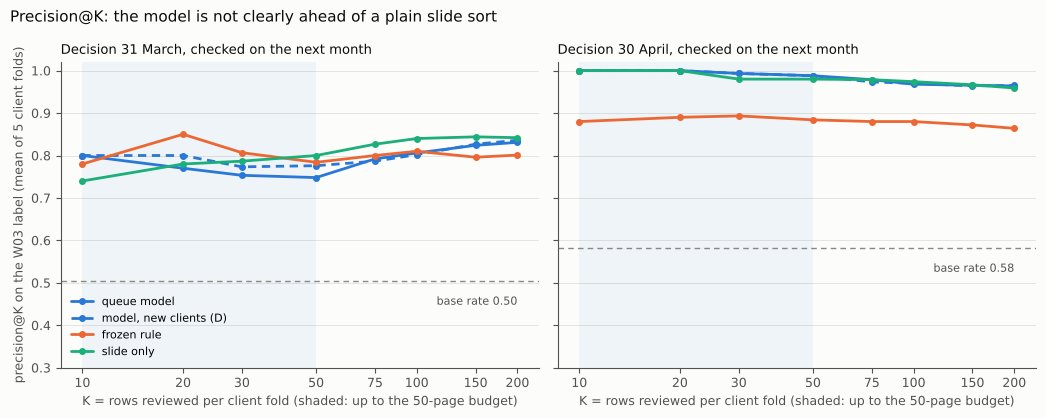

Saved ../figures/w07_precision_at_k.png


In [8]:
# Figure 1: precision@K on the W03 label (validation view, per-fold mean on the same client folds as W04 to W06)
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"     # validated categorical slots, fixed order
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.titlecolor": INK, "font.family": "sans-serif"})


def clean_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


STYLE = {"queue model (time-aware, C)": (BLUE, "-", "queue model"),
         "same model, test clients held out (D)": (BLUE, (0, (3, 2)), "model, new clients (D)"),
         "W04 rule (frozen)": (ORANGE, "-", "frozen rule"),
         "slide only (no model)": (AQUA, "-", "slide only")}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), facecolor=SURFACE, sharey=True)
for ax, run in zip(axes, RUNS):
    clean_axes(ax)
    curve = CURVES[run]
    ax.axvspan(K_GRID[0], BATCH, color=BLUE, alpha=0.06, linewidth=0)
    base = curve.loc["random order (base rate)", 50]
    ax.axhline(base, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.text(K_GRID[-1], base - 0.035, f"base rate {base:.2f}", color=INK_2, fontsize=8, ha="right", va="top")
    for method, (color, dash, short) in STYLE.items():
        ax.plot(K_GRID, curve.loc[method, K_GRID], color=color, linestyle=dash, linewidth=2, marker="o", markersize=4,
                solid_capstyle="round", label=short)
    ax.set_xscale("log")
    ax.set_xticks(K_GRID)
    ax.set_xticklabels(K_GRID)
    ax.minorticks_off()
    ax.set_ylim(0.3, 1.02)
    ax.set_title(f"Decision {run}, checked on the next month", loc="left", fontsize=9.5)
    ax.set_xlabel("K = rows reviewed per client fold (shaded: up to the 50-page budget)")
axes[0].set_ylabel("precision@K on the W03 label (mean of 5 client folds)")
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.suptitle("Precision@K: the model is not clearly ahead of a plain slide sort", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
FIG_PRECISION = FIG_DIR / "w07_precision_at_k.png"
fig.savefig(FIG_PRECISION, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Saved {FIG_PRECISION}")

**What the curve says.** On 31 March the model is not ahead where the budget sits: at K=50 it has 0.748 against 0.784 for the frozen rule and 0.800 for the slide sort (base rate 0.503). It is above the rule only at K=10 and from K=150 on. It is above the slide sort only at K=10. On 30 April the model and the slide sort are level near the top (0.988 and 0.980 at K=50) and both are well above the rule (0.884, base rate 0.581). The strict version (D) tells the same story. So the honest sentence is: **on the W03 label the model is a little below the rule in one month (0.748 vs 0.784) and well above it in the other (0.988 vs 0.884), but never clearly better than sorting by the slide.** That is why the model is not used on its own below.

### Archetypes, actions and the order

Each page gets one action. The action comes from a small set of gates checked in a fixed order. Every gate reuses a cut from an earlier week, none was tuned here.

| Step | Gate (checked in this order) | Action | Where the cut comes from |
|---|---|---|---|
| 1 | under 5 impressions a day in the second half of the month | `not_in_review_pool` (off the queue) | W05 review pool |
| 2 | no full previous month, so no known normal level (new or newly tracked page) | `wait_and_recheck` (off the queue, scored again next month) | W05 / W06 false alarms |
| 3 | the frozen rule fires but the second half is still at 80%+ of the previous month (a surge that ended) | `monitor_only` (on the queue, nobody edits it) | W04 surge check, same 20% cut |
| 4 | the rule gives `NO_FLAG` and no clicks were lost against the previous month | `no_action` (off the queue) | |
| 5 | one day holds 30%+ of the first half's impressions | `verify_then_review` (tracking or campaign check first) | W04 weak-pick check |
| 6 | the whole client's second half is under 80% of its previous month | `site_check_first` (one ticket per client) | W04 / W06 one-client problem |
| 7 | the rule fires and the page sits under 80% of its normal level | `review_for_refresh` | W04 rule + previous month |
| 8 | anything left: `NO_FLAG` from the rule but clicks were lost | `investigate_quiet_risk` (a person finds the reason) | |

**Reason codes.** The main reason is the frozen W04 rule: `sliding_with_demand` or `NO_FLAG`. Context codes tell the reviewer where to look: `below_normal_level`, `back_to_normal`, `clicks_down`, `low_ctr_for_position`, `one_day_spike`, `site_wide_drop`, `no_previous_month`.

**The order.** `priority = model score × clicks at stake`, where clicks at stake = clicks a day in the previous month minus clicks a day in the second half of this month (0 if clicks did not fall). The model gives the risk, the clicks give the size. Rows that need a person come first, `monitor_only` rows last. The first 50 rows that need a person are the monthly batch. The model score is an ordering score. I never checked its calibration, so it is not called a probability or a confidence.

The cell also asserts the gates on both runs, so the policy is code and not only text.

In [9]:
# What each action asks a person to do. Order of this dict = the order of actions in the queue tables
ACTIONS = {
    "review_for_refresh":     (True,  "the rule fired and the page sits below its own normal level: read the page, check the human-review questions, decide"),
    "investigate_quiet_risk": (True,  "the rule gives NO_FLAG but the page is high in the queue: find out what the model and the clicks see before any change"),
    "verify_then_review":     (True,  "one day holds 30%+ of the first half: check tracking, campaigns and the daily chart before content"),
    "site_check_first":       (True,  "the whole client is down 20%+: one site-level check (tracking, migration, season) before page work"),
    "monitor_only":           (False, "the rule fired but the page is back at its normal level after a surge: nobody edits it"),
    "no_action":              (False, "the rule gives NO_FLAG and no clicks were lost against the previous month: off the queue"),
    "wait_and_recheck":       (False, "no full previous month (new or newly tracked page): off the queue, scored again next month"),
    "not_in_review_pool":     (False, "under 5 impressions a day in the second half: off the queue (W05 pool)"),
}
QUEUE_ACTIONS = [a for a in ACTIONS if a not in ("no_action", "wait_and_recheck", "not_in_review_pool")]
NEEDS_PERSON = [a for a, (person, _) in ACTIONS.items() if person]


def build_playbook(frame, model, decision_day):
    """The playbook for one decision day. Reads only feature-month and previous-month columns, never a label.
    The frozen rule gives the reason, the model gives the risk and the clicks at stake give the size."""
    q = frame.drop(columns=["fold"]).copy()
    # 1. Reason: the frozen W04 rule
    slid = q["slide_pct"].ge(MIN_SLIDE_PCT)                      # NaN (no first-half impressions) counts as not slid
    fires = slid & q["late_per_day"].ge(MIN_LATE_PER_DAY)
    q["reason_code"] = np.where(fires, "sliding_with_demand", "NO_FLAG")
    # 2. Risk: the time-aware model score (an ordering score, not a calibrated probability)
    q["model_score"] = np.nan
    q.loc[q["in_pool"], "model_score"] = model.predict_proba(q.loc[q["in_pool"], FEATURES])[:, 1]
    # 3. Size: clicks a day lost against the page's own previous month (0 when clicks did not fall)
    q["clicks_at_stake_per_day"] = (q["prev_clicks_per_day"] - q["clicks_late_per_day"]).clip(lower=0)
    q["late_vs_prev"] = q["late_per_day"] / q["prev_per_day"]
    has_prev = q["prev_per_day"].notna()
    below = q["late_per_day"] < BELOW_NORMAL * q["prev_per_day"]
    spike = q["early_peak_share"].ge(SPIKE_SHARE)
    site = q[has_prev].groupby("client_hash_id")[["late_per_day", "prev_per_day"]].sum()
    site_drop = q["client_hash_id"].map(site["late_per_day"] < SITE_DROP * site["prev_per_day"]).eq(True)
    tier = pd.cut(q["avg_position"], CTR_TIERS, right=False)                       # tier medians from this month: known on the day
    q["tier_median_ctr_pct"] = tier.map(q.groupby(tier, observed=True)["ctr_pct"].median()).astype("float64")
    low_ctr = q["ctr_pct"] < q["tier_median_ctr_pct"]

    # 4. Gates, checked in this order, then the action. Spike and site gates only touch rows that would be reviewed
    stake = q["clicks_at_stake_per_day"] > 0
    q["action"] = np.select(
        [~q["in_pool"], ~has_prev, fires & ~below, ~fires & ~stake, spike, site_drop, fires],
        ["not_in_review_pool", "wait_and_recheck", "monitor_only", "no_action", "verify_then_review", "site_check_first", "review_for_refresh"],
        default="investigate_quiet_risk")

    # 5. Context codes: what a reviewer should look at first
    context = {"below_normal_level": has_prev & below, "back_to_normal": has_prev & ~below, "clicks_down": q["clicks_at_stake_per_day"] > 0,
               "low_ctr_for_position": low_ctr, "one_day_spike": spike, "site_wide_drop": site_drop, "no_previous_month": ~has_prev}
    codes = pd.Series("", index=q.index)
    for code, mask in context.items():
        codes = codes.where(~mask, codes + code + ";")
    q["context_codes"] = codes.str.rstrip(";").replace("", "none")

    # 6. Order: model score x clicks at stake. Rows that need a person first, monitor_only rows last
    q["priority"] = q["model_score"] * q["clicks_at_stake_per_day"]
    queue = q[q["action"].isin(QUEUE_ACTIONS)].copy()
    queue["needs_person"] = queue["action"].isin(NEEDS_PERSON)
    queue = queue.sort_values(["needs_person", "priority", "model_score", "content_hash_id"], ascending=[False, False, False, True])
    queue["queue_rank"] = np.arange(1, len(queue) + 1)
    queue["in_first_batch"] = queue["needs_person"] & (queue["needs_person"].cumsum() <= BATCH)
    q = q.join(queue[["queue_rank", "in_first_batch"]])
    q["queue_rank"] = q["queue_rank"].astype("Int64")
    q["in_first_batch"] = q["in_first_batch"].eq(True)
    q["decision_day"] = decision_day
    return q.sort_values(["queue_rank", "content_hash_id"], na_position="last").reset_index(drop=True)


PLAYBOOK = {run: build_playbook(FRAMES[RUN_SLICE[run]], QUEUE_MODEL[run], f"2026-{fm[-2:]}-{pd.Timestamp(fm + '-01').days_in_month}")
            for run, (fm, lm, pm) in RUNS.items()}

# The gates are asserted on both runs, so the policy is code and not only text
for run, q in PLAYBOOK.items():
    on_queue = q["queue_rank"].notna()
    assert not set(q.columns) & {LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"}, "a label is in the playbook"
    assert q.loc[on_queue, "prev_per_day"].notna().all(), "a page without a previous month is on the queue"
    assert q.loc[on_queue, "in_pool"].all(), "a page under the 5-a-day bar is on the queue"
    assert q.loc[q["context_codes"].str.contains("one_day_spike") & on_queue, "action"].isin(["verify_then_review", "monitor_only"]).all()
    assert (q.loc[q["reason_code"].eq("sliding_with_demand") & q["context_codes"].str.contains("back_to_normal"), "action"] == "monitor_only").all()
    assert q.loc[on_queue, "model_score"].notna().all() and q["reason_code"].notna().all()
    assert q["in_first_batch"].sum() == BATCH and not q.loc[q["in_first_batch"], "action"].eq("monitor_only").any()
print("PASS  gates asserted on both runs: no label, no young page, no page under the bar, spikes verified first, surges monitor only")

# Ranked actions for the 31 March run (and the counts for 30 April next to them)
main = PLAYBOOK["31 March"]
actions = (main.groupby("action").agg(pages=("content_hash_id", "size"), median_model_score=("model_score", "median"),
                                      median_clicks_at_stake=("clicks_at_stake_per_day", "median"), in_first_batch=("in_first_batch", "sum"))
           .reindex(ACTIONS))
actions["share of pages"] = actions["pages"] / len(main)
actions["pages on 30 April"] = PLAYBOOK["30 April"]["action"].value_counts().reindex(ACTIONS).fillna(0).astype(int)
actions["needs a person"] = [ACTIONS[a][0] for a in actions.index]
for run, q in PLAYBOOK.items():
    print(f"{run}: {len(q):,} pages, {int(q['queue_rank'].notna().sum()):,} on the queue | first batch of {BATCH}: "
          + ", ".join(f"{a} {n}" for a, n in q.loc[q["in_first_batch"], "action"].value_counts().items()))
actions.round(3)

PASS  gates asserted on both runs: no label, no young page, no page under the bar, spikes verified first, surges monitor only
31 March: 94,496 pages, 33,845 on the queue | first batch of 50: investigate_quiet_risk 25, review_for_refresh 23, verify_then_review 2
30 April: 99,868 pages, 48,612 on the queue | first batch of 50: review_for_refresh 28, site_check_first 9, investigate_quiet_risk 8, verify_then_review 5


,pages,median_model_score,median_clicks_at_stake,in_first_batch,share of pages,pages on 30 April,needs a person
action,,,,,,,
review_for_refresh,8542,0.344,0.036,23,0.090,14430,True
investigate_quiet_risk,16529,0.230,0.071,25,0.175,11003,True
verify_then_review,377,0.307,0.036,2,0.004,671,True
site_check_first,24,0.149,0.107,0,0.000,13998,True
monitor_only,8373,0.297,0.000,0,0.089,8510,False
no_action,29678,0.198,0.000,0,0.314,25322,False
wait_and_recheck,21069,0.219,NaN,0,0.223,10757,False
not_in_review_pool,9904,NaN,0.000,0,0.105,15177,False


**The ranked actions on 31 March.** Out of 94,496 pages, 33,845 are on the queue and 25,472 of them need a person. The other pages are off the queue for a stated reason: 29,678 have nothing flagged and no clicks lost (`no_action`), 21,069 are young (`wait_and_recheck`) and 9,904 are under the 5-a-day bar. 8,373 surge-ended pages sit on the queue as `monitor_only`. The first batch is 23 `review_for_refresh`, 25 `investigate_quiet_risk` and 2 `verify_then_review` rows.

On 30 April the mix moves: 13,998 pages go to `site_check_first` because 11 clients had their whole second half of April under 80% of their March level. That is the gate working as planned: those pages need one site-level look per client, not thousands of page reviews.

### The head of the 31 March queue

The first ten rows of the batch as a reviewer would see them. Clients appear by rank only, no hash ids.

In [10]:
# The head of the 31 March queue: the first batch, as a reviewer would see it (client by rank, no hash ids)
client_pages = main.groupby("client_hash_id").size().reset_index(name="n").sort_values(["n", "client_hash_id"], ascending=[False, True])
CLIENT_RANK = pd.Series(np.arange(1, len(client_pages) + 1), index=client_pages["client_hash_id"].to_numpy())
main["client_rank"] = main["client_hash_id"].map(CLIENT_RANK)
SHOW = ["queue_rank", "action", "reason_code", "context_codes", "model_score", "clicks_at_stake_per_day", "client_rank",
        "prev_per_day", "early_per_day", "late_per_day", "late_vs_prev", "prev_clicks_per_day", "clicks_late_per_day", "ctr_pct", "avg_position"]
batch = main[main["in_first_batch"]]
print(f"First batch on 31 March: {len(batch)} rows | actions: " + ", ".join(f"{a} {n}" for a, n in batch["action"].value_counts().items()))
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(batch[SHOW].head(10).set_index("queue_rank").round({"model_score": 3, "clicks_at_stake_per_day": 2, "prev_per_day": 0, "early_per_day": 0,
                                                              "late_per_day": 0, "late_vs_prev": 2, "prev_clicks_per_day": 2, "clicks_late_per_day": 2,
                                                              "ctr_pct": 2, "avg_position": 1}))
batch_clients = batch["client_rank"].value_counts()
print(f"Clients in the first batch: {batch['client_rank'].nunique()} | biggest share: client rank {batch_clients.index[0]} with {batch_clients.iloc[0]} of {BATCH} rows")

First batch on 31 March: 50 rows | actions: investigate_quiet_risk 25, review_for_refresh 23, verify_then_review 2


,action,reason_code,context_codes,model_score,clicks_at_stake_per_day,client_rank,prev_per_day,early_per_day,late_per_day,late_vs_prev,prev_clicks_per_day,clicks_late_per_day,ctr_pct,avg_position
queue_rank,,,,,,,,,,,,,,
1,investigate_quiet_risk,NO_FLAG,below_normal_level;clicks_down,0.199,38.57,4,5079.0,2298.0,1950.0,0.38,57.32,18.75,1.13,2.4
2,review_for_refresh,sliding_with_demand,below_normal_level;clicks_down,0.270,20.06,3,884.0,227.0,122.0,0.14,20.50,0.44,0.47,13.6
3,review_for_refresh,sliding_with_demand,below_normal_level;clicks_down,0.246,18.98,3,801.0,73.0,50.0,0.06,19.36,0.38,0.68,9.3
4,investigate_quiet_risk,NO_FLAG,below_normal_level;clicks_down,0.127,36.24,1,4631.0,1467.0,2432.0,0.53,57.93,21.69,1.05,2.1
5,investigate_quiet_risk,NO_FLAG,below_normal_level;clicks_down,0.185,22.80,3,887.0,42.0,38.0,0.04,23.18,0.38,0.89,11.9
6,investigate_quiet_risk,NO_FLAG,back_to_normal;clicks_down,0.199,18.94,1,4000.0,3106.0,4074.0,1.02,29.75,10.81,0.33,3.1
7,investigate_quiet_risk,NO_FLAG,back_to_normal;clicks_down,0.106,34.40,1,5975.0,4478.0,5449.0,0.91,118.21,83.81,1.62,3.0
8,review_for_refresh,sliding_with_demand,below_normal_level;clicks_down,0.282,12.62,3,441.0,163.0,107.0,0.24,13.00,0.38,0.55,5.7
9,review_for_refresh,sliding_with_demand,below_normal_level;clicks_down,0.196,15.04,3,814.0,187.0,123.0,0.15,15.54,0.50,0.59,20.7


Clients in the first batch: 4 | biggest share: client rank 3 with 20 of 50 rows


**Reading the first ten rows.** Every row lost real visits against its own February: from about 11 to 39 clicks a day. Eight of them are also far below their normal impressions (between 4% and 53% of February). Row 1 is a good example of a quiet risk. The rule gives `NO_FLAG` because the page did not slide inside March, but it was already at 38% of its February impressions and lost about 39 of its 57 clicks a day. Rows 6 and 7 are a different kind of quiet risk. Their impressions are back at normal (102% and 91%) but their clicks fell, which points at the title, the snippet or a change on the results page rather than at the content.

**One weak spot is visible right away:** only 4 clients fill the batch and two of them hold 37 of the 50 rows (client rank 3 has 20, client rank 1 has 17). Section 3 has a batch rule for that.

### The decay/refresh insight

The FlyRank paper's first playbook action is "refresh mature pages before they decay". My data can't show what a refresh does (W06 section 1: the paper's refresh effect is a snapshot comparison and our edit dates are a July snapshot). What it can show is **which drops are decay and which are noise**, using each page's own previous month as its normal level. The cell sorts the review pool into six kinds of pages and only then joins what happened next month.

In [11]:
# The decay/refresh insight: what happened next month to each kind of page (hindsight, joined only now)
def archetype(q):
    has_prev = q["prev_per_day"].notna()
    below = q["late_per_day"] < BELOW_NORMAL * q["prev_per_day"]
    slid = q["slide_pct"].ge(MIN_SLIDE_PCT)
    return pd.Series(np.select([~has_prev & slid, ~has_prev, slid & below, slid, below],
                               ["young page, slid", "young page, no slide", "slid, below its normal level",
                                "slid, back to normal (surge ended)", "no slide, already below normal"],
                               default="no slide, at or above normal"), index=q.index)


ARCHETYPES = ["slid, below its normal level", "slid, back to normal (surge ended)", "no slide, already below normal",
              "no slide, at or above normal", "young page, slid", "young page, no slide"]
decay_rows = []
for run, q in PLAYBOOK.items():
    s = RUN_SLICE[run]
    p = q[q["in_pool"]].copy()
    p["archetype"] = archetype(p)
    h = HIND[s].reindex(p["content_hash_id"])
    p[LABEL], p[STRICT_LABEL] = h[LABEL].to_numpy(), h[STRICT_LABEL].to_numpy()
    p["still_below_normal"] = (h["next_per_day"].to_numpy() < BELOW_NORMAL * p["prev_per_day"]).where(p["prev_per_day"].notna())
    p["above_month_level"] = h["next_per_day"].to_numpy() >= p["imp_per_day"]
    for a, g in p.groupby("archetype"):
        decay_rows.append({"run": run, "archetype": a, "pages": len(g), "share of pool": len(g) / len(p),
                           "declined (W03 label)": g[LABEL].mean(), "fell another 20% (strict)": g[STRICT_LABEL].mean(),
                           "still below normal next month": g["still_below_normal"].astype(float).mean(),
                           "back above this month's level": g["above_month_level"].mean(),
                           "median clicks a day": g["clicks_per_day"].median()})
DECAY = pd.DataFrame(decay_rows).set_index(["run", "archetype"])
DECAY = DECAY.reindex(pd.MultiIndex.from_product([list(RUNS), ARCHETYPES], names=["run", "archetype"]))
print("Review pool pages only. 'Normal level' = the page's previous month. Next-month numbers are hindsight")
DECAY.round(3)

Review pool pages only. 'Normal level' = the page's previous month. Next-month numbers are hindsight


pages  share of pool  \
run      archetype                                                  
31 March slid, below its normal level         8741          0.103   
         slid, back to normal (surge ended)   8373          0.099   
         no slide, already below normal       6015          0.071   
         no slide, at or above normal        40394          0.478   
         young page, slid                     4741          0.056   
         young page, no slide                16328          0.193   
30 April slid, below its normal level        24005          0.283   
         slid, back to normal (surge ended)   8510          0.100   
         no slide, already below normal      11123          0.131   
         no slide, at or above normal        30296          0.358   
         young page, slid                     3480          0.041   
         young page, no slide                 7277          0.086   

                                             declined (W03 label)  \
run      archetype                                                  
31 March slid, below its normal level                       0.723   
         slid, back to normal (surge ended)                 0.712   
         no slide, already below normal                     0.412   
         no slide, at or above normal                       0.441   
         young page, slid                                   0.715   
         young page, no slide                               0.374   
30 April slid, below its normal level                       0.753   
         slid, back to normal (surge ended)                 0.661   
         no slide, already below normal                     0.480   
         no slide, at or above normal                       0.434   
         young page, slid                                   0.820   
         young page, no slide                               0.476   

                                             fell another 20% (strict)  \
run      archetype                                                       
31 March slid, below its normal level                            0.461   
         slid, back to normal (surge ended)                      0.500   
         no slide, already below normal                          0.426   
         no slide, at or above normal                            0.522   
         young page, slid                                        0.515   
         young page, no slide                                    0.492   
30 April slid, below its normal level                            0.488   
         slid, back to normal (surge ended)                      0.470   
         no slide, already below normal                          0.486   
         no slide, at or above normal                            0.492   
         young page, slid                                        0.616   
         young page, no slide                                    0.577   

                                             still below normal next month  \
run      archetype                                                           
31 March slid, below its normal level                                0.839   
         slid, back to normal (surge ended)                          0.407   
         no slide, already below normal                              0.799   
         no slide, at or above normal                                0.272   
         young page, slid                                              NaN   
         young page, no slide                                          NaN   
30 April slid, below its normal level                                0.909   
         slid, back to normal (surge ended)                          0.367   
         no slide, already below normal                              0.867   
         no slide, at or above normal                                0.284   
         young page, slid                                              NaN   
         young page, no slide                               

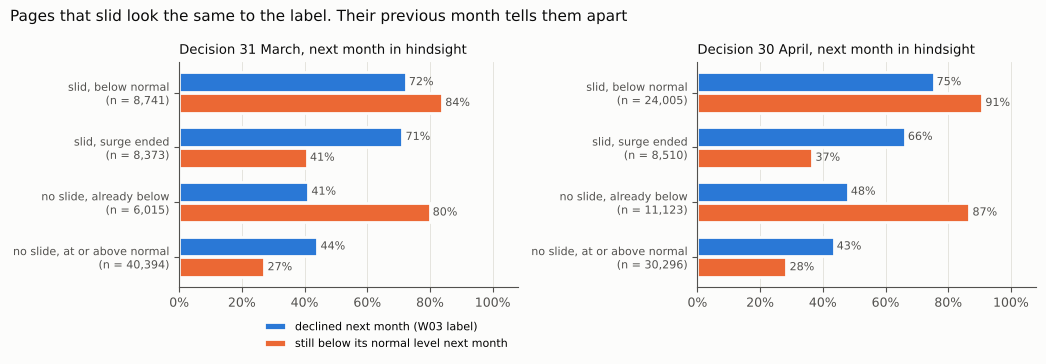

Saved ../figures/w07_decay_insight.png


In [12]:
# Figure 2: the W03 label scores a surge ending like real decay. The page's own previous level does not
SHOWN = ARCHETYPES[:4]
SHORT = {"slid, below its normal level": "slid, below normal", "slid, back to normal (surge ended)": "slid, surge ended",
         "no slide, already below normal": "no slide, already below", "no slide, at or above normal": "no slide, at or above normal"}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), facecolor=SURFACE)
y = np.arange(len(SHOWN))
for ax, run in zip(axes, RUNS):
    clean_axes(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    part = DECAY.loc[run].loc[SHOWN]
    for offset, column, color, name in [(-0.19, "declined (W03 label)", BLUE, "declined next month (W03 label)"),
                                        (0.19, "still below normal next month", ORANGE, "still below its normal level next month")]:
        bars = ax.barh(y + offset, part[column], height=0.36, color=color, edgecolor=SURFACE, linewidth=2, label=name)
        for bar, v in zip(bars, part[column]):
            ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.0%}", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{SHORT[a]}\n(n = {int(n):,})" for a, n in zip(SHOWN, part["pages"])], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.08)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(f"Decision {run}, next month in hindsight", loc="left", fontsize=9.5)
axes[0].legend(loc="lower right", frameon=False, fontsize=8, bbox_to_anchor=(1.0, -0.32), ncol=1)
fig.suptitle("Pages that slid look the same to the label. Their previous month tells them apart", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
FIG_DECAY = FIG_DIR / "w07_decay_insight.png"
fig.savefig(FIG_DECAY, dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()
print(f"Saved {FIG_DECAY}")

**What the table and the figure say.**

1. **The W03 label can't tell a surge ending from real decay.** On 31 March pages that slid and were below their normal level "declined" 72.3% of the time. Pages that slid but were back at normal after a surge "declined" 71.2% of the time. On 30 April it was 75.3% vs 66.1%. W04 found the same thing in its top 50.
2. **The previous month can.** 83.9% of the slid-and-below pages were still under 80% of their normal level a month later, against 40.7% of the surge-ended pages (90.9% vs 36.7% on 30 April). Pages that were already below normal without a late slide stayed down too (79.9% and 86.7%). Steady pages ended below normal only 27.2% and 28.4% of the time.
3. **So decay mostly does not fix itself within a month,** and that holds in both runs. This is the reason the playbook sends below-normal pages to a person and sends surge-ended pages to `monitor_only`.
4. **But nothing here forecasts a new fall.** "Fell another 20% after the decision day" (the strict W06 label) sits between 43% and 52% for every kind of page on 31 March, close to the 50% base rate of the pool. On 30 April only the young pages were higher (58% and 62%) and they are off the queue. The queue finds losses that already happened and stayed. It does not see the next one coming.

**What this means for refresh.** The refresh candidates are pages below their own normal level with visits at stake. Whether a refresh brings them back is not measured anywhere in this project. The honest way to find out is a controlled test: refresh part of the batch, leave comparable pages untouched and compare them 30, 60 and 90 days later (the paper's own "Measure" line). One more limit: the paper's age-based decay cliff (9 to 12 months) can't be checked in my frame, because the only date fields are a July snapshot. The playbook uses each page's own history instead of its age.

### Cost and value: does the model earn its place in the order?

The mentors' question for this week: would a plain rule create most of the value with less risk? To answer it I take the same rows (everything on the queue that needs a person) and order them five ways. Then I judge the first 50 rows of each order in hindsight with three measures:
- **declined (W03 label)**: the measure W04 to W06 used
- **still below normal next month**: did the loss last?
- **clicks a day still lost next month**: previous-month clicks a day minus next-month clicks a day, summed over the 50 rows. This is the visits at stake that did not come back on their own. It is not what a review would win back.

One honest note: I chose the playbook order after looking at both runs, so the numbers below are not a clean test. The sealed June month in the capstone is the first clean check.

In [13]:
# Cost and value: the same rows (everything on the queue that needs a person) ordered five ways, then judged in hindsight
ORDERS = {"playbook: model score x clicks at stake": ("priority", False),
          "model score only": ("model_score", False),
          "clicks at stake only (no model)": ("clicks_at_stake_per_day", False),
          "W04 rule (frozen)": ("rule_score", False),
          "slide only (no model)": ("late_half_share", True)}


def judged_rows(run):
    """Rows that need a person on this run's queue, with next-month hindsight joined (after every order is fixed)."""
    q = PLAYBOOK[run]
    rows = q[q["action"].isin(NEEDS_PERSON)].copy()
    rows["rule_score"] = sliding_with_demand(rows)
    h = HIND[RUN_SLICE[run]].reindex(rows["content_hash_id"])
    rows[LABEL], rows[STRICT_LABEL] = h[LABEL].to_numpy(), h[STRICT_LABEL].to_numpy()
    rows["still_below_normal"] = h["next_per_day"].to_numpy() < BELOW_NORMAL * rows["prev_per_day"]
    rows["clicks_still_lost"] = rows["prev_clicks_per_day"] - h["next_clicks_per_day"].to_numpy()   # vs the page's normal level
    return rows


def ordered(rows, order):
    column, ascending = ORDERS[order]
    return rows.sort_values([column, "content_hash_id"], ascending=[ascending, True])


value_rows, VALUE_CURVES = [], {}
for run in RUNS:
    rows = judged_rows(run)
    VALUE_CURVES[run] = {}
    for order in ORDERS:
        r = ordered(rows, order)
        VALUE_CURVES[run][order] = r["clicks_still_lost"].cumsum().to_numpy()[:200]
        top = r.head(BATCH)
        value_rows.append({"run": run, "order": order,
                           "declined (W03 label)": top[LABEL].mean(), "fell another 20% (strict)": top[STRICT_LABEL].mean(),
                           "still below normal next month": top["still_below_normal"].mean(),
                           "clicks a day at stake on the day": top["clicks_at_stake_per_day"].sum(),
                           "clicks a day still lost next month": top["clicks_still_lost"].sum(),
                           "rows with 0 clicks this month": (top["clicks_per_day"] == 0).mean(),
                           "biggest single-client share": top["client_hash_id"].value_counts().iloc[0] / BATCH})
VALUE = pd.DataFrame(value_rows).set_index(["run", "order"])
for run in RUNS:
    rows = judged_rows(run)
    batch_rows = PLAYBOOK[run][PLAYBOOK[run]["in_first_batch"]]
    print(f"{run}: the first batch is {BATCH} of {len(rows):,} rows that need a person ({BATCH / len(rows):.2%}) and holds "
          f"{batch_rows['clicks_at_stake_per_day'].sum() / rows['clicks_at_stake_per_day'].sum():.1%} of their clicks at stake on the day")
base = {run: HIND[RUN_SLICE[run]][LABEL].reindex(judged_rows(run)["content_hash_id"]).mean() for run in RUNS}
print(f"First {BATCH} rows of each order. Base rate of the W03 label on these rows: "
      + ", ".join(f"{run} {b:.3f}" for run, b in base.items()) + ". Next-month columns are hindsight")
VALUE.round(3)

31 March: the first batch is 50 of 25,472 rows that need a person (0.20%) and holds 11.2% of their clicks at stake on the day
30 April: the first batch is 50 of 40,102 rows that need a person (0.12%) and holds 6.8% of their clicks at stake on the day
First 50 rows of each order. Base rate of the W03 label on these rows: 31 March 0.531, 30 April 0.633. Next-month columns are hindsight


declined (W03 label)  \
run      order                                                           
31 March playbook: model score x clicks at stake                  0.50   
         model score only                                         0.84   
         clicks at stake only (no model)                          0.42   
         W04 rule (frozen)                                        0.92   
         slide only (no model)                                    0.98   
30 April playbook: model score x clicks at stake                  0.88   
         model score only                                         1.00   
         clicks at stake only (no model)                          0.78   
         W04 rule (frozen)                                        0.90   
         slide only (no model)                                    1.00   

                                                  fell another 20% (strict)  \
run      order                                                                
31 March playbook: model score x clicks at stake                       0.36   
         model score only                                              0.56   
         clicks at stake only (no model)                               0.30   
         W04 rule (frozen)                                             0.44   
         slide only (no model)                                         0.54   
30 April playbook: model score x clicks at stake                       0.56   
         model score only                                              0.46   
         clicks at stake only (no model)                               0.64   
         W04 rule (frozen)                                             0.60   
         slide only (no model)                                         0.48   

                                                  still below normal next month  \
run      order                                                                    
31 March playbook: model score x clicks at stake                           0.88   
         model score only                                                  0.82   
         clicks at stake only (no model)                                   0.76   
         W04 rule (frozen)                                                 0.82   
         slide only (no model)                                             0.96   
30 April playbook: model score x clicks at stake                           0.98   
         model score only                                                  0.96   
         clicks at stake only (no model)                                   0.94   
         W04 rule (frozen)                                                 0.90   
         slide only (no model)                                             1.00   

                                                  clicks a day at stake on the day  \
run      order                                                                       
31 March playbook: model score x clicks at stake                           491.866   
         model score only                                                    2.804   
         clicks at stake only (no model)                                   507.973   
         W04 rule (frozen)                                                  38.491   
         slide only (no model)                                               5.500   
30 April playbook: model score x clicks at stake                           487.178   
         model score only                                                    2.546   
         clicks at stake only (no model)                                   524.951   
         W04 rule (frozen)                                                 114.305   
         slide only (no model)                                              49.688   

                                                  clicks a day still lost next month  \
run      order                                                                         
31 Mar

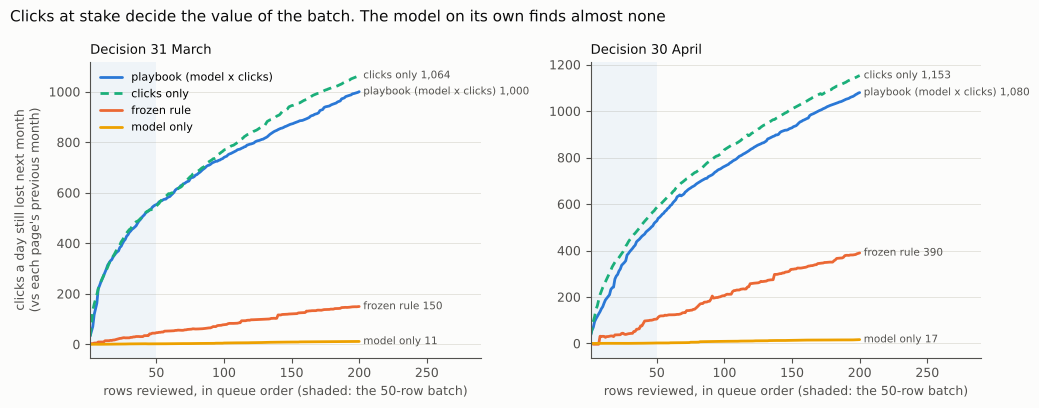

Saved ../figures/w07_batch_value.png


In [14]:
# Figure 3: clicks a day still lost next month, summed over the first K reviewed rows (hindsight)
VSTYLE = {"playbook: model score x clicks at stake": (BLUE, "-", "playbook (model x clicks)"),
          "clicks at stake only (no model)": (AQUA, (0, (3, 2)), "clicks only"),
          "W04 rule (frozen)": (ORANGE, "-", "frozen rule"),
          "model score only": (YELLOW, "-", "model only")}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1), facecolor=SURFACE)
k = np.arange(1, 201)
for ax, run in zip(axes, RUNS):
    clean_axes(ax)
    ax.axvspan(1, BATCH, color=BLUE, alpha=0.06, linewidth=0)
    for order, (color, dash, short) in VSTYLE.items():
        curve = VALUE_CURVES[run][order]
        ax.plot(k[:len(curve)], curve, color=color, linestyle=dash, linewidth=2, solid_capstyle="round", label=short)
        ax.text(k[len(curve) - 1] + 3, curve[-1], f"{short} {curve[-1]:,.0f}", color=INK_2, fontsize=7.5, va="center")
    ax.set_xlim(1, 290)
    ax.set_xlabel("rows reviewed, in queue order (shaded: the 50-row batch)")
    ax.set_title(f"Decision {run}", loc="left", fontsize=9.5)
axes[0].set_ylabel("clicks a day still lost next month\n(vs each page's previous month)")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Clicks at stake decide the value of the batch. The model on its own finds almost none", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
FIG_VALUE = FIG_DIR / "w07_batch_value.png"
fig.savefig(FIG_VALUE, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Saved {FIG_VALUE}")

**What the comparison says.**

- **On the W03 label the playbook batch looks worse.** On 31 March only 50% of its rows "declined" against 84% for the model order and 92% for the frozen rule (base rate on these rows 0.531). On 30 April it is 88% against 100% and 90% (base rate 0.633).
- **On value it is far ahead.** The playbook batch held 553 clicks a day that were still lost the next month (527 on 30 April). The model order held about 2, the frozen rule 46 (105) and the slide sort 6 (49). The model order fills its batch with small pages: 52% and 66% of its rows had no click at all in the month.
- **Most of that value comes from the clicks, not the model.** Ordering by clicks at stake alone gets 546 and 585. The model weight changes the batch a little: a higher share still below normal next month (88% vs 76%, then 98% vs 94%) and more labeled decliners (50% vs 42%, then 88% vs 78%), for about the same clicks on 31 March and 10% fewer on 30 April. That is a small, positive trade in two months. It is not proof that the model is needed, so section 4 gives it a fallback.
- **The value is concentrated.** On 31 March the batch is 0.20% of the 25,472 rows that need a person but holds 11.2% of their clicks at stake (0.12% and 6.8% on 30 April). Ordering by clicks is what makes 50 reviews a month matter.
- **The label and the value disagree. I follow the value.** The W03 label counts a 20% drop on a page with 30 impressions a day the same as on a page losing 50 clicks a day. With 50 reviews a month the second kind is the one worth a person's time.

In [15]:
# The value as a scenario, with its arithmetic printed (descriptive, from these two months, not a forecast)
REVIEW_MINUTES = 20          # ASSUMPTION: about 20 minutes for one person to check one row with the review questions
scenario = []
for run in RUNS:
    play = VALUE.loc[(run, "playbook: model score x clicks at stake")]
    for other in ["model score only", "W04 rule (frozen)"]:
        alt = VALUE.loc[(run, other)]
        scenario.append({"run": run, "compared with": other,
                         "extra labeled decliners in the batch": (play["declined (W03 label)"] - alt["declined (W03 label)"]) * BATCH,
                         "extra clicks a day still lost, found by the batch": play["clicks a day still lost next month"] - alt["clicks a day still lost next month"]})
SCENARIO = pd.DataFrame(scenario).set_index(["run", "compared with"])
hours = BATCH * REVIEW_MINUTES / 60
print(f"One batch = {BATCH} rows x {REVIEW_MINUTES} min = {hours:.1f} reviewer hours (assumption)")
for run in RUNS:
    play = VALUE.loc[(run, "playbook: model score x clicks at stake")]
    print(f"{run}: the playbook batch held {play['clicks a day still lost next month']:.0f} clicks a day still lost next month "
          f"= about {play['clicks a day still lost next month'] / hours:.0f} per reviewer hour, before any fix (none is measured here)")
SCENARIO.round(1)

One batch = 50 rows x 20 min = 16.7 reviewer hours (assumption)
31 March: the playbook batch held 553 clicks a day still lost next month = about 33 per reviewer hour, before any fix (none is measured here)
30 April: the playbook batch held 527 clicks a day still lost next month = about 32 per reviewer hour, before any fix (none is measured here)


extra labeled decliners in the batch  \
run      compared with                                             
31 March model score only                                  -17.0   
         W04 rule (frozen)                                 -21.0   
30 April model score only                                   -6.0   
         W04 rule (frozen)                                  -1.0   

                            extra clicks a day still lost, found by the batch  
run      compared with                                                         
31 March model score only                                               551.2  
         W04 rule (frozen)                                              507.3  
30 April model score only                                               525.4  
         W04 rule (frozen)                                              422.4

**The value as a scenario, not a promise.** With 50 reviews a month and about 20 minutes each (my assumption), one batch costs about 17 reviewer hours. In these two runs that batch pointed at about 530 to 550 clicks a day that were lost and stayed lost, about 32 to 33 per reviewer hour. Against the model order that is about 525 to 550 more clicks a day of lasting loss in front of a reviewer, but 17 fewer labeled decliners on 31 March and 6 fewer on 30 April.

Assumptions this depends on: the portfolio behaves like these two months, review time really is the bottleneck and a lost click is worth an editor's attention. What it does not include: any traffic won back. That needs the controlled test above.

**Cost of each kind of mistake:**

| Mistake | What it costs | How the playbook limits it |
|---|---|---|
| A row that recovers on its own (false alarm) | about 20 minutes of review, plus a needless rewrite if nobody checks | human review first. In these runs 6 of 50 rows (31 March) and 1 of 50 (30 April) recovered to normal |
| A real loss ranked low (miss) | the clicks keep leaking until the next monthly run | the queue reruns every month. W06: misses are mostly pages that grew first, which nothing in the month shows |
| The wrong action, such as editing a page that was only a surge | a working page gets disturbed | surge-ended pages are `monitor_only` and nobody edits them |
| A prune, redirect or noindex on a young page that would have come back | high and hard to undo | never automated (section 3) |

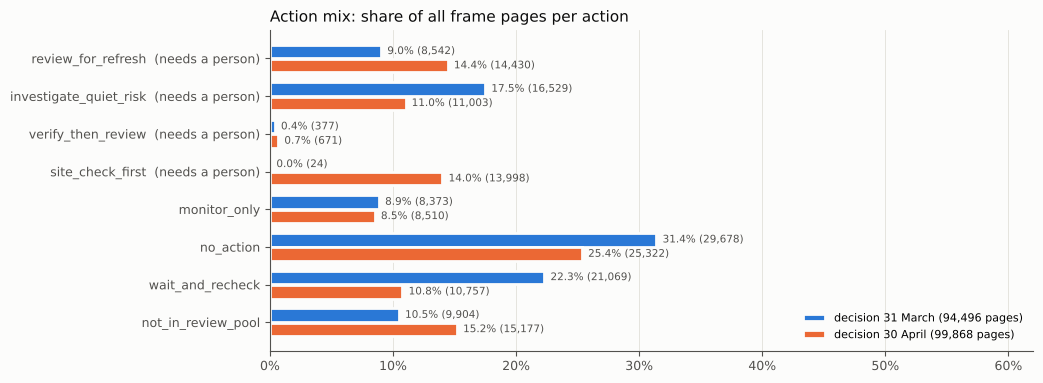

Saved ../figures/w07_action_mix.png


In [16]:
# Figure 4: the action mix of each run (all pages in the frame)
fig, ax = plt.subplots(figsize=(10.5, 3.9), facecolor=SURFACE)
clean_axes(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.6)
names = list(ACTIONS)
y = np.arange(len(names))
for offset, run, color in [(-0.19, "31 March", BLUE), (0.19, "30 April", ORANGE)]:
    counts = PLAYBOOK[run]["action"].value_counts().reindex(names).fillna(0)
    share = counts / counts.sum()
    bars = ax.barh(y + offset, share, height=0.36, color=color, edgecolor=SURFACE, linewidth=2, label=f"decision {run} ({int(counts.sum()):,} pages)")
    for bar, s, n in zip(bars, share, counts):
        ax.text(s + 0.005, bar.get_y() + bar.get_height() / 2, f"{s:.1%} ({int(n):,})", va="center", fontsize=7.5, color=INK_2)
ax.set_yticks(y)
ax.set_yticklabels([f"{a}{'  (needs a person)' if ACTIONS[a][0] else ''}" for a in names])
ax.invert_yaxis()
ax.set_xlim(0, 0.62)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.legend(loc="lower right", frameon=False, fontsize=8)
ax.set_title("Action mix: share of all frame pages per action", loc="left", fontsize=11, color=INK)
fig.tight_layout()
FIG_MIX = FIG_DIR / "w07_action_mix.png"
fig.savefig(FIG_MIX, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Saved {FIG_MIX}")

**The action mix.** About a third of the pages need nothing (31.4% on 31 March), about a fifth wait for a full month of history (22.3%) and only 9.0% are `review_for_refresh`. On 30 April the share of `site_check_first` jumps to 14.0% when 11 clients drop as a whole against March. The young share halves because more clients now have a full previous month. The team never reviews thousands of rows: the batch takes 50 a month from the top. The mix shows where the rest went and why.

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use, in one card** (model-card style, the facts in the cell below):

| | |
|---|---|
| **Who uses it** | a FlyRank content reviewer or SEO lead who plans the monthly review of about 50 pages across clients |
| **When** | once a month, a few days after month end (GSC data arrives 2 to 3 days late) |
| **Decision it supports** | which pages to look at first and which kind of check to start with. A person makes every decision |
| **Output** | a ranked CSV: action, reason code, context codes, model score, clicks at stake and the numbers behind them |
| **Data** | GSC daily data from the pseudonymized warehouse release. One month of features, the month before as the normal level. No GA4, no content text, no edit dates |
| **Covers** | pages with 100+ impressions in the month, a row on every day and a client tracked since day 1. 38 of the 104 clients on 31 March, 44 on 30 April |
| **Checked how** | W06: time-aware and client-grouped splits on two month pairs. Here: two monthly runs judged in hindsight |
| **Not for** | forecasting new drops, promising recovery, judging writers or clients, client-facing reports, pages or clients outside the coverage |

In [17]:
# The facts the intended-use card rests on (both runs)
dim_clients = con.sql(f"SELECT COUNT(*) AS n FROM read_parquet('{REL}/dim_clients.parquet')").df()["n"].iloc[0]
card = {}
for run, q in PLAYBOOK.items():
    on_queue = q["queue_rank"].notna()
    card[run] = {"pages in the frame (W03 contract)": len(q), "clients in the frame": q["client_hash_id"].nunique(),
                 "clients in the release": int(dim_clients), "pages on the queue": int(on_queue.sum()),
                 "rows that need a person": int(q["action"].isin(NEEDS_PERSON).sum()),
                 "first batch": int(q["in_first_batch"].sum()),
                 "off the queue: young pages": int((q["action"] == "wait_and_recheck").sum()),
                 "off the queue: under the 5-a-day bar": int((q["action"] == "not_in_review_pool").sum()),
                 "model trained on": f"{TRAIN_SLICE[run]} review pool ({len(POOLS[TRAIN_SLICE[run]]):,} pages)"}
pd.DataFrame(card)

,31 March,30 April
pages in the frame (W03 contract),94496,99868
clients in the frame,38,44
clients in the release,104,104
pages on the queue,33845,48612
rows that need a person,25472,40102
first batch,50,50
off the queue: young pages,21069,10757
off the queue: under the 5-a-day bar,9904,15177
model trained on,"Feb→Mar review pool (60,290 pages)","Mar→Apr review pool (84,592 pages)"


**Limits, each tied to a claim above:**

1. **Two month pairs is thin evidence.** Every number here comes from two decision days. They are the same months W06 used. The sealed June month (capstone) is the first clean test. A rolling backtest over more months is the most useful missing experiment.
2. **One month is a short normal level.** If the previous month was itself unusual (a surge, a holiday), "below normal" is wrong for that page. A longer baseline (two or three months) would be stronger.
3. **Nothing here is causal.** The batch points at visits that were lost and stayed lost. It does not show that a refresh, a new title or anything else would bring them back.
4. **Absence from the queue is not health.** Pages under the floor, young pages and clients without a full month are simply not judged.
5. **Survivorship.** The frame keeps pages with a row on every day of both months, so clients or pages that stopped are not in it.
6. **The model score is not calibrated.** It is used to order rows, never as a probability or a threshold.
7. **Concentration.** A few big clients fill the head of the queue. The scores and the batch rules are only as fair as that mix allows.

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Every row gets a quick human review before anything changes.** The queue helps a person decide what to look at. It never authorizes a rewrite. These are the questions for every row (the first three come from the live session, the last two from my W04 to W06 errors):

1. Did a special event, a season or a campaign cause the change?
2. Is the page still about what people are searching for?
3. Is the client changing things right now (a migration, a redesign, new pages)?
4. Is this a real drop below the page's normal level, or one big day, on the daily chart?
5. Did a sibling page of the same client gain what this one lost (consolidation)?

**Per action, the first check:**

| Action | First check | Then |
|---|---|---|
| `review_for_refresh` | the five questions | if all clear: write a hypothesis (what is out of date or missing) and plan a change. Log it |
| `investigate_quiet_risk` | why are clicks down with no slide? Compare impressions vs clicks. If impressions held, look at the title, snippet and results page first | only then decide if content is the problem |
| `verify_then_review` | tracking, campaign or bot traffic behind the one big day | if the spike was real traffic, review like a refresh row |
| `site_check_first` | one look at the whole client: tracking, migration, season, an update | only after that, pick single pages |
| `monitor_only` | nothing to do. Look again next month | any override is logged with a reason |

**What to log for every reviewed row:** accept or reject, the reason, what was changed and the date. This log is what a future before/after test needs. It is also the missing join for "recently edited pages" below.

**The no-go list: what should NOT be automated**
- No automatic rewrite, refresh or AI-generated update pushed live. Ever.
- No automatic prune, delete, merge, redirect or noindex. These are hard to undo and young pages often come back.
- No bulk title or meta description changes from the queue.
- No page-by-page work on a client that dropped as a whole before the site check.
- No editing of `monitor_only` pages, because they are back at normal after a surge.
- No use of the score or "declined" as a forecast or a promise of recovery in a client report.
- No ranking of writers, teams or clients by the score.
- No retraining and shipping a new model without the post-label check in section 4.

The table below says where each policy lives: **asserted** (checked by code in this notebook), **upstream** (enforced by the W03 data contract), **proposed** (written down, not built) or **by design**.

In [18]:
# Batch rules applied to the 31 March batch, then one review card as a reviewer would get it
POLICIES = pd.DataFrame([
    ("no automatic rewrite, prune, redirect or noindex, ever", "by design", "the notebook writes a CSV and nothing else. No step touches a site"),
    ("pages under 100 impressions a month stay out", "upstream", "W03 data contract (rule 3 of the frame)"),
    ("pages under 5 impressions a day in the second half stay out", "asserted", "W05 review pool, checked in build_playbook"),
    ("new pages (no full previous month) stay out: wait_and_recheck", "asserted", "assert in the playbook cell"),
    ("surge ended (rule fired, back to normal): monitor_only, never a rewrite", "asserted", "assert in the playbook cell"),
    ("one-day spikes (30%+ of the first half): verify_then_review first", "asserted", "assert in the playbook cell"),
    ("whole client down 20%+: site_check_first, one ticket per client", "asserted", "site_drop gate in build_playbook"),
    ("more than 10 batch rows from one client: one site-level look first", "proposed", "printed below for the batch, not enforced in code"),
    ("pages edited in the last 8 weeks stay out", "proposed", "needs an edit-history join; dim_content is a July snapshot (W03), so not built"),
], columns=["policy", "status", "where it lives"]).set_index("policy")
with pd.option_context("display.max_colwidth", 100, "display.width", 250):
    display(POLICIES)

per_client = batch["client_rank"].value_counts()
crowded = per_client[per_client > 10]
print(f"Batch rule (proposed): clients with more than 10 of the {BATCH} batch rows: "
      + (", ".join(f"client rank {c} ({n} rows)" for c, n in crowded.items()) if len(crowded) else "none"))
print("Context codes in the batch: " + ", ".join(f"{c} {int(batch['context_codes'].str.contains(c).sum())}"
                                              for c in ["below_normal_level", "back_to_normal", "clicks_down", "low_ctr_for_position", "one_day_spike", "site_wide_drop"]))


def review_card(row):
    """What a reviewer gets for one row: the numbers known on the day, the reason, the action and the questions."""
    lines = [f"Queue rank {int(row['queue_rank'])} | client rank {int(row['client_rank'])} | action: {row['action']}",
             f"Reason (frozen rule): {row['reason_code']} | context: {row['context_codes']}",
             f"Model score {row['model_score']:.3f} (ordering score, not a probability) | clicks at stake {row['clicks_at_stake_per_day']:.1f} a day",
             f"Impressions a day: previous month {row['prev_per_day']:,.0f} | first half {row['early_per_day']:,.0f} | second half {row['late_per_day']:,.0f} "
             f"({row['late_vs_prev']:.0%} of normal)",
             f"Clicks a day: previous month {row['prev_clicks_per_day']:.1f} | second half {row['clicks_late_per_day']:.1f} | CTR {row['ctr_pct']:.2f}% at position {row['avg_position']:.1f}",
             "Before any change: 1) daily chart vs last month: real drop or one event?  2) season, campaign or site change?",
             "  3) does the page still match what people search for?  4) is the client changing things right now?",
             "  5) did a sibling page gain what this one lost?  Log: accept / reject, why, what was done, date"]
    return "\n".join(lines)


print()
print(review_card(batch.iloc[0]))

,status,where it lives
policy,,
"no automatic rewrite, prune, redirect or noindex, ever",by design,the notebook writes a CSV and nothing else. No step touches a site
pages under 100 impressions a month stay out,upstream,W03 data contract (rule 3 of the frame)
pages under 5 impressions a day in the second half stay out,asserted,"W05 review pool, checked in build_playbook"
new pages (no full previous month) stay out: wait_and_recheck,asserted,assert in the playbook cell
"surge ended (rule fired, back to normal): monitor_only, never a rewrite",asserted,assert in the playbook cell
one-day spikes (30%+ of the first half): verify_then_review first,asserted,assert in the playbook cell
"whole client down 20%+: site_check_first, one ticket per client",asserted,site_drop gate in build_playbook
more than 10 batch rows from one client: one site-level look first,proposed,"printed below for the batch, not enforced in code"
pages edited in the last 8 weeks stay out,proposed,"needs an edit-history join; dim_content is a July snapshot (W03), so not built"


Batch rule (proposed): clients with more than 10 of the 50 batch rows: client rank 3 (20 rows), client rank 1 (17 rows)
Context codes in the batch: below_normal_level 42, back_to_normal 8, clicks_down 50, low_ctr_for_position 2, one_day_spike 2, site_wide_drop 0

Queue rank 1 | client rank 4 | action: investigate_quiet_risk
Reason (frozen rule): NO_FLAG | context: below_normal_level;clicks_down
Model score 0.199 (ordering score, not a probability) | clicks at stake 38.6 a day
Impressions a day: previous month 5,079 | first half 2,298 | second half 1,950 (38% of normal)
Clicks a day: previous month 57.3 | second half 18.8 | CTR 1.13% at position 2.4
Before any change: 1) daily chart vs last month: real drop or one event?  2) season, campaign or site change?
  3) does the page still match what people search for?  4) is the client changing things right now?
  5) did a sibling page gain what this one lost?  Log: accept / reject, why, what was done, date


**What the batch rules say for 31 March.** The proposed batch rule fires: client rank 3 has 20 of the 50 rows and client rank 1 has 17. Before a reviewer opens 37 pages of two sites, one site-level look at each (what changed in March?) is cheaper and may explain most of them. No batch row is a site-wide drop (that gate only caught 24 pages of 3 clients in March). 42 of the 50 rows are below their normal level, 8 are back at normal but lost clicks and 2 have a one-day spike.

**Status, honestly:** five gates are asserted in code, the volume floor is upstream in the W03 contract, two policies are only proposed (the crowded-batch rule and the recently-edited exclusion, which needs edit history the release does not have) and "no automatic changes" holds by design because the notebook only writes a CSV.

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

**Two clocks.** Some checks can run before a queue goes out. Others only become possible after the next month's labels arrive. Those can change the *next* queue, not the one already sent.

| Clock | What is checked | Status |
|---|---|---|
| Pre-release (decision day) | population: pages, clients, pool size vs last run. Schema: features complete, no label column. Feature drift: PSI of the five features vs last run. Gate counts: young share, site-wide drops, batch concentration | implemented in this notebook as a harness, not a production monitor |
| Post-label (a month later) | base rate vs the training month. Model vs frozen rule vs slide sort on the label. Batch persistence and clicks still lost | implemented here for the two runs |
| Thresholds | the numbers in `THRESHOLDS` and the trigger table | proposed policy to validate on more months, not a shipped system |

**Retrain and fallback policy (proposed).** The queue model is refitted every month on the last labeled month, which is what both runs did. Two fallbacks keep the complexity honest: if the model's P@50 is below the frozen rule for two labeled months in a row, drop the model and order by clicks at stake only. If the playbook batch is less persistent than the clicks-only batch for two labeled months in a row, drop the model weight too. Monthly refitting itself is a policy to validate, not a tested mitigation.

In [19]:
def psi(reference, current, bins=10):
    """Population stability index of one feature: current month vs reference month, on reference deciles."""
    ref, cur = pd.Series(reference).dropna(), pd.Series(current).dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))


# Proposed thresholds: a policy to validate, not a shipped system
THRESHOLDS = {"pool size change vs last run": 0.25, "feature PSI": 0.25, "share of pool pages off the queue as young": 0.25,
              "clients with a site-wide drop": 1, "biggest single-client share of the batch": 0.5,
              "base-rate move vs the training month": 0.10, "batch still below normal next month (floor)": 0.70}

PRE, POST = {}, {}
for run in RUNS:
    s, ref = RUN_SLICE[run], TRAIN_SLICE[run]
    q, cur_pool, ref_pool = PLAYBOOK[run], POOLS[s], POOLS[ref]
    in_pool = q[q["in_pool"]]
    # Clock 1: pre-release, checkable on the decision day
    PRE[run] = {"pages in the frame": len(q), "clients in the frame": q["client_hash_id"].nunique(),
                "pool size change vs last run": len(cur_pool) / len(ref_pool) - 1,
                "schema: features complete in the pool": bool(cur_pool[FEATURES].notna().all().all()),
                "schema: no label column in the playbook": not set(q.columns) & {LABEL, STRICT_LABEL},
                **{f"PSI {f}": psi(ref_pool[f], cur_pool[f]) for f in FEATURES},
                "share of pool pages off the queue as young": (in_pool["action"] == "wait_and_recheck").mean(),
                "clients with a site-wide drop": int(q.loc[q["action"] == "site_check_first", "client_hash_id"].nunique()),
                "biggest single-client share of the batch": q[q["in_first_batch"]]["client_hash_id"].value_counts().iloc[0] / BATCH}
    # Clock 2: post-label, only after the next month's outcomes arrive
    rows = judged_rows(run)
    play = VALUE.loc[(run, "playbook: model score x clicks at stake")]
    POST[run] = {"pool base rate, training month": labels(ref, ref_pool).mean(), "pool base rate, this run": labels(s, cur_pool).mean(),
                 "base-rate move vs the training month": labels(s, cur_pool).mean() - labels(ref, ref_pool).mean(),
                 "model P@50 (C, fold mean)": CURVES[run].loc["queue model (time-aware, C)", 50],
                 "frozen rule P@50 (fold mean)": CURVES[run].loc["W04 rule (frozen)", 50],
                 "slide only P@50 (fold mean)": CURVES[run].loc["slide only (no model)", 50],
                 "batch still below normal next month": play["still below normal next month"],
                 "batch clicks a day still lost next month": play["clicks a day still lost next month"],
                 "clicks-only order: still below normal": VALUE.loc[(run, "clicks at stake only (no model)"), "still below normal next month"]}
print("Clock 1, pre-release (known on the decision day)")
display(pd.DataFrame(PRE).round(3))
print("Clock 2, post-label (known a month later)")
pd.DataFrame(POST).round(3)

Clock 1, pre-release (known on the decision day)


,31 March,30 April
pages in the frame,94496,99868
clients in the frame,38,44
pool size change vs last run,0.403085,0.00117
schema: features complete in the pool,True,True
schema: no label column in the playbook,True,True
PSI imp_per_day_log,0.009978,0.012638
PSI ctr_pct,0.008754,0.00265
PSI avg_position,0.105305,0.048253
PSI late_half_share,0.077393,0.32946
PSI gsc_days,0.264027,0.027099


Clock 2, post-label (known a month later)


,31 March,30 April
"pool base rate, training month",0.240,0.497
"pool base rate, this run",0.497,0.573
base-rate move vs the training month,0.257,0.076
"model P@50 (C, fold mean)",0.748,0.988
frozen rule P@50 (fold mean),0.784,0.884
slide only P@50 (fold mean),0.800,0.980
batch still below normal next month,0.880,0.980
batch clicks a day still lost next month,553.095,527.419
clicks-only order: still below normal,0.760,0.940


In [20]:
def fired(value, limit, above=True):
    return bool(value > limit) if above else bool(value < limit)


TRIGGER_SPECS = [  # (clock, trigger, how to read it from PRE / POST, limit, fires when above?, what to do)
    ("pre-release", "pool size moved more than 25% vs last run", lambda pre, post: abs(pre["pool size change vs last run"]), 0.25, True,
     "check the pipeline and the new clients before release"),
    ("pre-release", "a feature PSI above 0.25 vs last run", lambda pre, post: max(pre[f"PSI {f}"] for f in FEATURES), THRESHOLDS["feature PSI"], True,
     "hold the release until a person reads the drift"),
    ("pre-release", "more than 25% of pool pages are young", lambda pre, post: pre["share of pool pages off the queue as young"], 0.25, True,
     "expect a thin queue for new clients and say so in the release note"),
    ("pre-release", "at least one client with a site-wide drop", lambda pre, post: pre["clients with a site-wide drop"], 0.5, True,
     "open one site ticket per client before page work"),
    ("pre-release", "one client holds more than half of the batch", lambda pre, post: pre["biggest single-client share of the batch"], 0.5, True,
     "look at the site first, then spread the batch"),
    ("post-label", "base rate moved more than 0.10 vs the training month", lambda pre, post: abs(post["base-rate move vs the training month"]), 0.10, True,
     "pause the NEXT release for review (it cannot undo this one)"),
    ("post-label", "model P@50 below the frozen rule (model minus rule)", lambda pre, post: post["model P@50 (C, fold mean)"] - post["frozen rule P@50 (fold mean)"], 0, False,
     "two labeled months in a row: drop the model, order by clicks at stake only"),
    ("post-label", "batch still below normal next month under 70%", lambda pre, post: post["batch still below normal next month"], 0.70, False,
     "the gates let noise in: revisit the 80% cut and the one-month baseline"),
    ("post-label", "playbook below the clicks-only order on persistence (difference)", lambda pre, post: post["batch still below normal next month"] - post["clicks-only order: still below normal"], 0, False,
     "two labeled months in a row: drop the model weight"),
]
trigger_rows = []
for clock, name, read, limit, above, then in TRIGGER_SPECS:
    row = {"clock": clock, "trigger": name}
    for run in RUNS:
        value = float(read(PRE[run], POST[run]))
        row[f"{run}: value"], row[f"{run}: fired"] = round(value, 3), fired(value, limit, above)
    row["if it fires"] = then
    trigger_rows.append(row)
TRIGGERS = pd.DataFrame(trigger_rows).set_index(["clock", "trigger"])
worst_psi = {run: max(FEATURES, key=lambda f: PRE[run][f"PSI {f}"]) for run in RUNS}
print("Worst PSI feature per run: " + ", ".join(f"{run} {f} ({PRE[run]['PSI ' + f]:.3f})" for run, f in worst_psi.items()))
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    display(TRIGGERS)

# The fallback policy over the two labeled months we have
below_rule = [bool(POST[run]["model P@50 (C, fold mean)"] < POST[run]["frozen rule P@50 (fold mean)"]) for run in RUNS]
print(f"Model below the frozen rule: {dict(zip(RUNS, below_rule))} -> fallback {'TRIGGERED' if all(below_rule) else 'not triggered (needs two labeled months in a row)'}")

Worst PSI feature per run: 31 March gsc_days (0.264), 30 April late_half_share (0.329)


31 March: value  31 March: fired  30 April: value  30 April: fired                                                                 if it fires
clock       trigger                                                                                                                                                                                                         
pre-release pool size moved more than 25% vs last run                                   0.403             True            0.001            False                       check the pipeline and the new clients before release
            a feature PSI above 0.25 vs last run                                        0.264             True            0.329             True                             hold the release until a person reads the drift
            more than 25% of pool pages are young                                       0.249            False            0.127            False          expect a thin queue for new clients and say so in the release note
            at least one client with a site-wide drop                                   3.000             True           11.000             True                            open one site ticket per client before page work
            one client holds more than half of the batch                                0.400            False            0.280            False                               look at the site first, then spread the batch
post-label  base rate moved more than 0.10 vs the training month                        0.257             True            0.076            False                 pause the NEXT release for review (it cannot undo this one)
            model P@50 below the frozen rule (model minus rule)                        -0.036             True            0.104            False  two labeled months in a row: drop the model, order by clicks at stake only
            batch still below normal next month under 70%                               0.880            False            0.980            False      the gates let noise in: revisit the 80% cut and the one-month baseline
            playbook below the clicks-only order on persistence (difference)            0.120            False            0.040            False                          two labeled months in a row: drop the model weight

Model below the frozen rule: {'31 March': True, '30 April': False} -> fallback not triggered (needs two labeled months in a row)


**What the two clocks would have said.**

- **Run 1 (31 March), before release:** three pre-release triggers fire. The pool grew 40.3% against the training slice, because the March frame has 12 more clients than the February one (38 vs 26). The `gsc_days` feature drifted (PSI 0.264). I have not traced the cause. The new clients are the first suspect. And 3 clients dropped as a whole against February (24 pages went to site checks). Under the proposed policy a person reads the drift before the queue goes out.
- **Run 1, after April's labels:** the base rate in the pool moved from 0.240 (the Feb→Mar training month) to 0.497, a move of 0.257. The proposed alarm would have paused the *next* release (30 April) for review. The model was also 0.036 below the frozen rule on P@50. The batch itself held up: 88% of it was still below normal in April.
- **Run 2 (30 April):** `late_half_share` drifted hard (PSI 0.329) and 11 clients had their second half of April under 80% of their March level. The site gate sent 13,998 pages to 11 site checks. After May's labels the base rate moved only 0.076, the model was 0.104 above the rule and 98% of the batch stayed below normal.
- **Fallbacks:** the model was below the rule in one labeled month, not two, so the fallback is not triggered. The playbook batch was more persistent than the clicks-only batch in both runs (+0.12 and +0.04), so the model weight stays for now.

**The honest reading:** the alarms fired often in two months and the second run still turned out fine. So these thresholds would mostly cost a review, not catch a disaster. Monthly GSC data is noisy and a PSI of 0.25 may be too tight for it. More months are needed before any of these numbers becomes policy.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

The paper next week builds on these files. The queue CSV is regenerated by this notebook and stays out of git by design (`work/**/*.csv` is gitignored and CI blocks dataset files). The figures and the metrics receipt are small, hold no page ids and are committed.

In [21]:
# Exports for the paper: the 31 March queue (regenerated, gitignored), four figures and the metrics receipt (committed)
EXPORT_COLUMNS = ["decision_day", "queue_rank", "in_first_batch", "action", "reason_code", "context_codes", "model_score",
                  "clicks_at_stake_per_day", "priority", "content_hash_id", "client_hash_id", "client_rank",
                  "prev_per_day", "early_per_day", "late_per_day", "late_vs_prev", "slide_pct", "prev_clicks_per_day",
                  "clicks_late_per_day", "ctr_pct", "tier_median_ctr_pct", "avg_position"]
queue_path = OUT_DIR / "w07_action_queue.csv"
main[EXPORT_COLUMNS].round(4).to_csv(queue_path, index=False)

written = pd.read_csv(queue_path, nrows=5).columns
assert not any(c in written for c in [LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"]), "hindsight in the CSV"
assert all(Path(p).exists() for p in [FIG_PRECISION, FIG_DECAY, FIG_VALUE, FIG_MIX])


def clean(v):
    # JSON-safe value: floats rounded, NaN written as null
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, float, np.floating, np.integer)):
        return None if pd.isna(v) else round(float(v), 4)
    return v


def table_dict(t):
    return {" | ".join(map(str, k)) if isinstance(k, tuple) else str(k): {c: clean(v) for c, v in row.items()} for k, row in t.iterrows()}


receipt_out = {
    "notebook": "work/notebooks/w07_action_playbook.ipynb",
    "run_date": str(date.today()),
    "versions": VERSIONS,
    "seed": SEED,
    "decision_days": {run: {"feature_month": fm, "label_month_hindsight": lm, "previous_month": pm, "model_trained_on": TRAIN_SLICE[run]}
                      for run, (fm, lm, pm) in RUNS.items()},
    "sealed_month": "2026-06, never read",
    "playbook": {"reason": "frozen W04 rule sliding_with_demand (else NO_FLAG)",
                 "order": "model score x clicks at stake per day; rows that need a person first",
                 "model": {"name": "logistic regression", "features": FEATURES, "training": "previous slice review pool, all clients (W06 design C)"},
                 "clicks_at_stake": "previous-month clicks per day minus second-half clicks per day, floored at 0",
                 "cuts": {"below_normal": BELOW_NORMAL, "spike_share": SPIKE_SHARE, "site_drop": SITE_DROP, "min_slide_pct": MIN_SLIDE_PCT,
                          "min_late_per_day": MIN_LATE_PER_DAY, "ctr_tiers": CTR_TIERS, "batch": BATCH}},
    "policies": {p: {"status": r["status"], "where": r["where it lives"]} for p, r in POLICIES.iterrows()},
    "action_counts": {run: {k: int(v) for k, v in q["action"].value_counts().reindex(ACTIONS).fillna(0).items()} for run, q in PLAYBOOK.items()},
    "first_batch_actions": {run: {k: int(v) for k, v in q.loc[q["in_first_batch"], "action"].value_counts().items()} for run, q in PLAYBOOK.items()},
    "precision_at_k_fold_mean": {run: {m: {str(k): round(float(v), 4) for k, v in row.items()} for m, row in CURVES[run].iterrows()} for run in RUNS},
    "decay_insight": table_dict(DECAY),
    "batch_value": table_dict(VALUE),
    "value_scenario": {"review_minutes_assumption": REVIEW_MINUTES, **table_dict(SCENARIO)},
    "monitoring": {"thresholds_proposed": THRESHOLDS, "pre_release": {r: {k: clean(v) for k, v in PRE[r].items()} for r in RUNS},
                   "post_label": {r: {k: clean(v) for k, v in POST[r].items()} for r in RUNS},
                   "triggers": {" | ".join(k): {c: clean(v) for c, v in row.items()} for k, row in TRIGGERS.iterrows()}},
    "exports": {"queue_csv": f"work/outputs/{queue_path.name}", "figures": [f"work/figures/{Path(p).name}" for p in [FIG_PRECISION, FIG_DECAY, FIG_VALUE, FIG_MIX]]},
}
receipt_path = OUT_DIR / "w07_action_playbook_metrics.json"
receipt_path.write_text(json.dumps(receipt_out, indent=2, ensure_ascii=False, default=str))
for p in [queue_path, FIG_PRECISION, FIG_DECAY, FIG_VALUE, FIG_MIX, receipt_path]:
    print(f"Wrote {p}  ({Path(p).stat().st_size / 1024:,.0f} KB)")
print(f"Queue rows: {len(main):,} pages, {int(main['queue_rank'].notna().sum()):,} on the queue. CSV files stay out of git (work/**/*.csv)")

Wrote ../outputs/w07_action_queue.csv  (18,639 KB)
Wrote ../figures/w07_precision_at_k.png  (132 KB)
Wrote ../figures/w07_decay_insight.png  (124 KB)
Wrote ../figures/w07_batch_value.png  (162 KB)
Wrote ../figures/w07_action_mix.png  (124 KB)
Wrote ../outputs/w07_action_playbook_metrics.json  (19 KB)
Queue rows: 94,496 pages, 33,845 on the queue. CSV files stay out of git (work/**/*.csv)


| File | What it is | In git? | Used in the paper for |
|---|---|---|---|
| `work/outputs/w07_action_queue.csv` | the 31 March playbook: 94,496 pages with action, reason code, context codes, model score, clicks at stake, priority and queue rank (33,845 on the queue, 50 in the first batch) | no, regenerated | the ranked recommendations section and any example rows (clients by rank only) |
| `work/figures/w07_precision_at_k.png` | precision@K, model vs frozen rule vs slide sort, both runs | yes | the validation result and its limit |
| `work/figures/w07_decay_insight.png` | label vs "still below normal" by kind of page, both runs | yes | the decay/refresh finding |
| `work/figures/w07_batch_value.png` | clicks still lost in the first K rows for four orders, both runs | yes | the cost/value argument |
| `work/figures/w07_action_mix.png` | share of pages per action, both runs | yes | what the queue does with every page |
| `work/outputs/w07_action_playbook_metrics.json` | every number in this notebook | yes | the receipt the paper's numbers trace back to |

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

**Checked against "what done looks like":**

- [x] Intended use: section 2, a model-card style table with who, when, the decision, the coverage and what it is not for
- [x] Ranked actions with reason codes: section 1, eight actions from a fixed gate order. The frozen W04 rule gives the reason, the model and the clicks at stake give the order. The first ten rows and a review card are shown
- [x] Archetype → action mapping: section 1, the gate table and the six kinds of pages in the decay table
- [x] The decay/refresh insight: section 1, the label vs the page's own previous month in two runs, with what it does not show
- [x] Human review: section 3, five questions for every row, a first check per action and what to log
- [x] Monitoring / retrain triggers: section 4, pre-release and post-label checks run on both runs, proposed thresholds and two fallback rules
- [x] Cost / value: section 1, five orders judged on the same rows, the value scenario with its assumptions and the cost of each mistake
- [x] No-go cases: section 3, what must never be automated, with each policy's status (asserted, upstream, proposed, by design)
- [x] Exports the queue for the paper: section 5, the CSV (gitignored) plus four committed figures and the metrics receipt
- [x] Practical and non-production: a monthly CSV for a person, no serving, no automatic actions. June stays sealed for the capstone